<img src="https://images.seeklogo.com/logo-png/28/1/u-cayetano-heredia-logo-png_seeklogo-289967.png" alt="LOGO UPCH" width=250 align="right">

<br>
<h1><font color="#7F000E" size=5>UNIVERSIDAD PERUANA CAYETANO HEREDIA</font></h1>
<h1><font color="#7F000E" size=6>SEÑALES BIOMÉDICAS</font></h1>
<h1><font color="#7F000E" size=4>LAB 12 —Tratamiento de la señal EEG, ritmos cerebrales, filtro ICA y extracción de características</font></h1>
<br>
<br>
<div style="text-align:right">
<font color="#7F000E" size=3> Curso: Introducción a las Señales Biomédicas</font><br>
<font color="#7F000E" size=3> Registros: 7 archivos EEG de un participante (BITalino, 08/05/2026)</font><br>
<font color="#7F000E" size=3> Versión para el docente</font><br>
</div>

| Campo | Completar |
|---|---|
| **Nombre del estudiante** | ✍️ |
| **Código** | ✍️ |
| **Grupo** | ✍️ |
| **Fecha** | ✍️ |

> **Material base:** clase *Tratamiento de señal EEG* (Mg. Lewis De La Cruz) · Ejemplo de MNE-Python [*Removing muscle ICA components*](https://mne.tools/stable/auto_examples/preprocessing/muscle_ica.html) · Laboratorio de adquisición de EEG con BITalino.

## 🔑 Cómo usar el laboratorio

Después de cada pregunta ✍️ hay una celda **✅ Respuesta**, construida **solo con las salidas visibles** del cuaderno. Las respuestas que dependen de la teoría y no de estos datos se marcan como *(conceptual)*. El cuestionario final incluye las **celdas de código que lo resuelven**, y hay una celda 🔎 de verificación adicional en B.8.

### Resumen de resultados (grupo de referencia)

| Aspecto | Resultado |
|---|---|
| Archivos | 7 registros de 1 canal, Fs = **100 Hz** (Nyquist 50 Hz), 32–84 s, sin paquetes perdidos |
| Dispositivos | **78:F6**: Basal1, ojos_abiertos, basal2 · **2A:08**: parpadeo_masticacion, basal3, música relajante y estresante |
| Interferencias | **40 Hz** (alias de 60 Hz) en los 4 registros de 2A:08, de 45 a 403 veces sobre sus vecinos · líneas en **4.6, 9.15 y 25 Hz** en 78:F6 |
| Saturación (techo del ADC en 1018) | ojos_abiertos 3.15 % (solo los primeros 3 s) · parpadeo 2.63 % · estresante 1.00 % · relajante 0.18 % |
| Banda dominante | No hay alfa dominante con ojos cerrados (montaje frontal Fp1–Fp2) |
| ICA de un canal (Wavelet-ICA) | Corrige transitorios en 4 registros; quita el 5.8 % de la varianza en parpadeo y ~0 % en los basales |
| Clasificación de 5 condiciones | Mejor F1 = **0.714** (Random Forest); azar = 0.20 |
| ⚠️ Variable de confusión | El **dispositivo** se predice con F1 = 0.99–1.00 a partir de las mismas características |

<a id="indice"></a>
# 📑 Índice de contenido

> 💡 En Colab también puedes navegar con el panel **"Índice"** (ícono ☰ de la barra izquierda).

**[Introducción](#intro)** — ¿Qué haremos? · El EEG en una página · Nuestros datos · Agenda

**[⚙️ Configuración](#config)**

**[🅰️ PARTE A — Conociendo nuestros datos](#parteA)** *(≈ 15 min)*
- [A.1 Subir los archivos e inventario automático](#A1)
- [A.2 Lectura, conversión a µV y saturación](#A2)
- [A.3 Primer vistazo: las señales en el tiempo](#A3)
- [A.4 Primer vistazo al espectro: ¿y ese pico en 40 Hz?](#A4)
- [A.5 Control de calidad automático](#A5)
- [A.6 Conclusiones de la Parte A](#A6)

**[🅱️ PARTE B — Tratamiento y extracción de características](#parteB)** *(≈ 40 min)*
- [B.1 El pipeline de procesamiento](#B1)
- [B.2 Filtrado](#B2)
- [B.3 Ritmos cerebrales: delta, theta, alfa, beta y gamma](#B3)
- [B.4 Filtro ICA: separar el cerebro de los artefactos](#B4)
- [B.5 Normalización y segmentación en épocas](#B5)
- [B.6 Extracción de características](#B6)
- [B.7 La tabla de características](#B7)
- [B.8 Clasificación y una advertencia importante](#B8)
- [B.9 Conclusiones de la Parte B](#B9)

**[📝 Cuestionario final: experimenta con tus datos](#cuestionario)** *(≈ 5 min o como tarea)*

**[📦 Entregables y referencias](#entregables)**

<a id="intro"></a>
# Introducción

## 🎯 ¿Qué haremos hoy?

**Objetivo: limpiar la señal EEG, analizar sus ritmos cerebrales y extraer características que permitan distinguir el estado del participante.**

Seguiremos el pipeline de la clase:

```
Señal fisiológica → Filtrado → Limpieza (ICA) → Preprocesamiento (normalización) → Extracción de características → Ingeniería de características
```

## 🧠 El EEG en una página

**¿Qué es?** El electroencefalograma es la actividad eléctrica registrada en el cuero cabelludo. La generan los **potenciales post-sinápticos** de grandes poblaciones de neuronas de la corteza cerebral que se activan de forma **sincronizada**.

**¿Qué tan grande es?** Muy pequeña: **20–100 µV** en el cuero cabelludo, unas **10 a 50 veces menos** que el ECG. Por eso el EEG es tan sensible al ruido y a los artefactos.

**Ritmos cerebrales.** El EEG se describe por **bandas de frecuencia**, y cada una se asocia a estados distintos:

| Banda | Frecuencia | Estado asociado |
|---|---|---|
| **Delta (δ)** | 0.5 – 4 Hz | Sueño profundo |
| **Theta (θ)** | 4 – 8 Hz | Somnolencia, meditación profunda |
| **Alfa (α)** | 8 – 13 Hz | Relajación con **ojos cerrados**; disminuye al abrir los ojos |
| **Beta (β)** | 13 – 30 Hz | Alerta, concentración, ojos abiertos |
| **Gamma (γ)** | > 30 Hz | Procesamiento cognitivo complejo; muy contaminada por actividad muscular |

> 📖 **Definición fácil:** imagina el EEG como el sonido de una orquesta. Cada banda es una sección de instrumentos: los contrabajos (delta) tocan lento y grave; los violines (beta, gamma), rápido y agudo. Analizar bandas es medir **qué tan fuerte suena cada sección**.

**Artefactos.** Son señales que **no vienen del cerebro** pero aparecen en el registro:

| Artefacto | Origen | Cómo se ve |
|---|---|---|
| **Parpadeo / movimiento ocular** | El ojo es un dipolo eléctrico; se mueve cerca de Fp1/Fp2 | Ondas lentas y grandes (< 4 Hz) |
| **Muscular (EMG)** | Músculos temporal, masetero y frontal (masticar, apretar) | Actividad rápida y "peluda" (> 20 Hz) |
| **Red eléctrica** | Instalación eléctrica (Perú: 60 Hz) | Oscilación de frecuencia fija |

## 🫀 Nuestros datos

Un participante registró su EEG con BITalino usando una **derivación frontal**: electrodo positivo en **Fp1**, negativo en **Fp2** y referencia en **O2**. Es **un solo canal**.

| Archivo | Condición | Duración aprox. |
|---|---|---|
| `Basal1.txt` | Reposo, **ojos cerrados** y cubiertos | 1 min |
| `ojos_abiertos.txt` | Ojos abiertos, mirada fija en un punto | 1 min |
| `basal2.txt` | Reposo con ojos cerrados, después de abrir los ojos | 30 s |
| `parpadeo_masticacion.txt` | Parpadeo rápido y masticación continua (**artefactos a propósito**) | 1 min |
| `basal3.txt` | Reposo con ojos cerrados, después de los artefactos | 30 s |
| `musica_relajante.txt` | Ojos cerrados escuchando música relajante | 1 min |
| `musica_estresante.txt` | Ojos cerrados escuchando música estresante | 1 min |

El cuaderno reconoce la condición por palabras clave en el nombre del archivo: `basal`, `ojos`, `parpadeo`/`mastic`, `relaj`, `estres`. No importan las mayúsculas.

## ⏱️ Agenda (60 min)

| Parte | Contenido | Minutos |
|---|---|---:|
| Configuración | Librerías y carga de archivos | 0 – 5 |
| **A** | Conocer los datos: inventario, saturación, espectro y calidad | 5 – 20 |
| **B** | Filtrado → bandas → ICA → épocas → características → clasificación | 20 – 55 |
| Cuestionario | Experimentos con tus datos | 55 – 60 (o tarea) |

<a id="config"></a>
# ⚙️ Configuración

| Librería | Para qué la usamos |
|---|---|
| `numpy`, `pandas` | Números y tablas |
| `matplotlib` | Gráficas |
| `scipy.signal` | Filtros y espectro (método de Welch) |
| `pywt` (PyWavelets) | Descomposición wavelet (para el ICA de un canal) |
| `scikit-learn` | FastICA, clasificadores y validación |

In [ ]:
# PyWavelets no siempre viene en Colab: se instala solo si falta
try:
    import pywt
except ImportError:
    !pip install -q PyWavelets
    import pywt

import os, re, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import skew, kurtosis
from sklearn.decomposition import FastICA

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (14, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.titleweight": "bold", "font.size": 11})
np.random.seed(0)

ORDEN = ["basal", "ojos_abiertos", "parpadeo_masticacion", "musica_relajante", "musica_estresante"]
COLOR = {"basal": "tab:blue", "ojos_abiertos": "tab:orange", "parpadeo_masticacion": "tab:red",
         "musica_relajante": "tab:green", "musica_estresante": "tab:purple"}
BANDAS = {"delta": (1, 4), "theta": (4, 8), "alfa": (8, 13), "beta": (13, 30), "gamma": (30, 45)}
COLOR_BANDA = {"delta": "#4C72B0", "theta": "#55A868", "alfa": "#C44E52", "beta": "#8172B2", "gamma": "#CCB974"}
print("✅ Librerías listas | PyWavelets", pywt.__version__)

✅ Librerías listas | PyWavelets 1.8.0


---
<a id="parteA"></a>
# 🅰️ PARTE A — Conociendo nuestros datos *(≈ 15 min)*

> **Idea central:** antes de aplicar ICA o calcular características, **revisamos los datos**. En el EEG esto es todavía más importante que en el ECG: la señal es diminuta y cualquier problema de adquisición puede ser más grande que el propio cerebro.

[⬆️ Volver al índice](#indice)

<a id="A1"></a>
## A.1 Subir los archivos e inventario automático

Ejecuta la celda. En Colab se abrirá un botón para **subir tus archivos `.txt`**; puedes seleccionarlos todos a la vez. El cuaderno:
1. Busca todos los `.txt` cuyo sensor sea **EEG** (lo lee en la cabecera).
2. Deduce la **condición** a partir del nombre del archivo.

> Si no hay archivos, se generan **registros simulados** solo para poder recorrer el cuaderno.

In [ ]:
def condicion_desde_nombre(nombre):
    n = nombre.lower()
    if "basal" in n:                       return "basal"
    if "ojos" in n:                        return "ojos_abiertos"
    if "parpad" in n or "mastic" in n:     return "parpadeo_masticacion"
    if "relaj" in n:                       return "musica_relajante"
    if "estres" in n:                      return "musica_estresante"
    return os.path.splitext(os.path.basename(n))[0]

def leer_cabecera(ruta):
    with open(ruta, "r", encoding="utf-8", errors="ignore") as f:
        lineas = [f.readline() for _ in range(3)]
    return list(json.loads(lineas[1].lstrip("# ").strip()).values())[0]

def buscar_archivos():
    filas = []
    for ruta in sorted(glob.glob("*.txt")):
        try:
            meta = leer_cabecera(ruta)
        except Exception:
            continue
        if any("EEG" in s.upper() for s in meta.get("sensor", [])):
            filas.append({"archivo": ruta, "condicion": condicion_desde_nombre(ruta)})
    return pd.DataFrame(filas, columns=["archivo", "condicion"])

inventario = buscar_archivos()
if len(inventario) == 0:
    try:
        from google.colab import files
        print("📤 Sube tus archivos .txt de OpenSignals (selecciónalos todos a la vez):")
        files.upload()
        inventario = buscar_archivos()
    except ImportError:
        pass

MODO_DEMO = inventario["condicion"].nunique() < 2 if len(inventario) else True
print("Modo:", "⚠️ DEMOSTRACIÓN (datos simulados)" if MODO_DEMO else "✅ datos reales del grupo")


Modo: ✅ datos reales del grupo


In [ ]:
import os
import glob

# Buscar y borrar archivos duplicados con el sufijo ' (1)'
archivos_duplicados = glob.glob("*/content/* (1)*") + glob.glob("* (1)*")
for archivo in archivos_duplicados:
    try:
        os.remove(archivo)
        print(f"❌ Eliminado: {archivo}")
    except Exception as e:
        print(f"⚠️ No se pudo eliminar {archivo}: {e}")

# Actualizar y mostrar el inventario limpio
inventario = buscar_archivos()
inventario["orden"] = inventario["condicion"].map(lambda c: ORDEN.index(c) if c in ORDEN else 99)
inventario = inventario.sort_values(["orden", "archivo"]).drop(columns="orden").reset_index(drop=True)
print(f"\nSe encontraron {len(inventario)} archivos únicos de EEG:")
display(inventario)

❌ Eliminado: preguntas_emma (1).txt
❌ Eliminado: musica_tranquila_emma (1).txt
❌ Eliminado: musica_hard_emma (1).txt
❌ Eliminado: basal_emma (1).txt

Se encontraron 5 archivos únicos de EEG:


,archivo,condicion
0,basal_emma.txt,basal
1,abre_cierra_emma.txt,abre_cierra_emma
2,musica_hard_emma.txt,musica_hard_emma
3,musica_tranquila_emma.txt,musica_tranquila_emma
4,preguntas_emma.txt,preguntas_emma


In [ ]:
# ---- Solo en modo demostración: genera 3 registros EEG simulados ----
def generar_eeg_demo(ruta, alfa, beta, parpadeos, emg, dur=60, fs=100, semilla=0):
    rng = np.random.default_rng(semilla)
    t = np.arange(int(dur * fs)) / fs
    x = np.cumsum(rng.standard_normal(len(t))) * 0.05                     # fondo 1/f
    x = signal.detrend(x) + 1.5 * rng.standard_normal(len(t))
    def ritmo(lo, hi):                                                   # ruido filtrado: ritmo "ancho", no una línea
        b, a = signal.butter(4, [lo, hi], "bandpass", fs=fs)
        r = signal.filtfilt(b, a, rng.standard_normal(len(t)))
        return r / r.std()
    x += alfa * ritmo(8, 12) + beta * ritmo(15, 25)
    for tp in rng.uniform(1, dur - 1, parpadeos):                        # parpadeos
        x += 25 * np.exp(-((t - tp)**2) / (2 * 0.08**2))
    if emg:                                                              # ráfagas musculares
        env = (np.sin(2*np.pi*0.8*t) > 0.3).astype(float)
        b, a = signal.butter(4, [20, 45], "bandpass", fs=fs)
        x += emg * env * signal.lfilter(b, a, rng.standard_normal(len(t)))
    adc = np.clip(np.round((x / 1e6 * 41782 / 3.3 + 0.5) * 1024), 0, 1023).astype(int)
    meta = {"demo": {"sensor": ["EEGBITREV"], "column": ["nSeq", "I1", "I2", "O1", "O2", "A4"], "label": ["A4"],
                     "sampling rate": fs, "resolution": [4, 1, 1, 1, 1, 10], "date": "DEMO", "time": "00:00:00",
                     "device name": "DEMO"}}
    with open(ruta, "w") as f:
        f.write("# OpenSignals Text File Format\n# " + json.dumps(meta) + "\n# EndOfHeader\n")
        f.writelines(f"{i % 16}\t0\t0\t0\t0\t{v}\t\n" for i, v in enumerate(adc))

if MODO_DEMO:
    generar_eeg_demo("DEMO_basal.txt", alfa=4, beta=0.5, parpadeos=0, emg=0, semilla=1)
    generar_eeg_demo("DEMO_ojos_abiertos.txt", alfa=1, beta=1.5, parpadeos=15, emg=0, semilla=2)
    generar_eeg_demo("DEMO_parpadeo_masticacion.txt", alfa=1, beta=1, parpadeos=50, emg=6, semilla=3)
    inventario = buscar_archivos()

inventario["orden"] = inventario["condicion"].map(lambda c: ORDEN.index(c) if c in ORDEN else 99)
inventario = inventario.sort_values(["orden", "archivo"]).drop(columns="orden").reset_index(drop=True)
print(f"Se encontraron {len(inventario)} archivos de EEG:")
display(inventario)

Se encontraron 5 archivos de EEG:


,archivo,condicion
0,basal_emma.txt,basal
1,abre_cierra_emma.txt,abre_cierra_emma
2,musica_hard_emma.txt,musica_hard_emma
3,musica_tranquila_emma.txt,musica_tranquila_emma
4,preguntas_emma.txt,preguntas_emma


<a id="A2"></a>
## A.2 Lectura, conversión a µV y saturación

La función `leer_eeg` lee la cabecera de cada archivo (frecuencia de muestreo, resolución, dispositivo, hora) y convierte las cuentas del ADC a **microvoltios** con la fórmula del sensor EEG de BITalino:

$$
EEG_{\mu V} = \frac{\left(\dfrac{ADC}{2^{n}} - \dfrac{1}{2}\right) \cdot V_{CC}}{G_{EEG}} \times 10^{6}, \qquad V_{CC}=3.3\,V,\; G_{EEG}=41\,782,\; n = 10\ \text{bits}
$$

La ganancia es enorme (41 782, frente a 1 100 del ECG), porque la señal es diminuta. Consecuencias:
- **Rango medible:** apenas **±39.5 µV**. Un parpadeo fuerte o un movimiento **satura** el conversor fácilmente.
- **Resolución:** 1 cuenta del ADC equivale a **0.077 µV**.

**Saturación:** cuando la señal supera el rango, el ADC se "pega" en su mínimo (0) o en su máximo. En estos registros el valor máximo que alcanza el ADC es **1018** (no 1023), así que contamos como saturadas las muestras en **0** o **≥ 1018**.

In [ ]:
def formato_hora(texto):
    try:
        return ":".join(f"{int(p):02d}" for p in str(texto).split(".")[0].split(":"))
    except ValueError:
        return str(texto)

def leer_eeg(ruta):
    meta = leer_cabecera(ruta)
    columnas, sensores, etiquetas = meta["column"], meta.get("sensor", []), meta.get("label", [])
    canal = next((e for s, e in zip(sensores, etiquetas) if "EEG" in s.upper()), etiquetas[0])
    idx = columnas.index(canal)
    n_bits = meta["resolution"][idx]
    datos = pd.read_csv(ruta, sep=r"\s+", comment="#", header=None).iloc[:, :len(columnas)]
    adc = datos.iloc[:, idx].to_numpy(dtype=float)
    nseq = datos.iloc[:, 0].to_numpy(dtype=int)
    saturada = (adc <= 0) | (adc >= 2**n_bits - 6)        # rieles del ADC: 0 y ~1018
    fs = int(meta["sampling rate"])
    return {"adc": adc, "eeg_uV": ((adc / 2**n_bits) - 0.5) * 3.3 / 41782 * 1e6, "fs": fs,
            "saturada": saturada, "canal": canal, "bits": n_bits,
            "dispositivo": str(meta.get("device name", "-"))[-5:], "hora": formato_hora(meta.get("time", "-")),
            "perdidos": int(np.sum((np.diff(nseq) % 16) != 1))}

senales, filas = {}, []
for _, fila in inventario.iterrows():
    r = leer_eeg(fila.archivo)
    senales[fila.archivo] = r
    seg_sat = np.unique((np.flatnonzero(r["saturada"]) / r["fs"]).astype(int))
    filas.append({"archivo": fila.archivo, "condición": fila.condicion, "dispositivo": r["dispositivo"],
                  "hora": r["hora"], "duración (s)": round(len(r["adc"]) / r["fs"], 1), "Fs (Hz)": r["fs"],
                  "paquetes perdidos": r["perdidos"], "muestras saturadas": int(r["saturada"].sum()),
                  "% saturado": round(100 * r["saturada"].mean(), 2),
                  "segundos con saturación": ", ".join(map(str, seg_sat[:12])) + (" ..." if len(seg_sat) > 12 else "")})
tabla_lectura = pd.DataFrame(filas).sort_values("hora").reset_index(drop=True)
FS = int(tabla_lectura["Fs (Hz)"].iloc[0])
assert (tabla_lectura["Fs (Hz)"] == FS).all(), "Todos los archivos deben tener la misma frecuencia de muestreo."
print(f"Frecuencia de muestreo: {FS} Hz  →  frecuencia de Nyquist = {FS/2:.0f} Hz")
display(tabla_lectura)

Frecuencia de muestreo: 1000 Hz  →  frecuencia de Nyquist = 500 Hz


,archivo,condición,dispositivo,hora,duración (s),Fs (Hz),paquetes perdidos,muestras saturadas,% saturado,segundos con saturación
0,basal_emma.txt,basal,0C:26,15:02:32,90.5,1000,0,31174,34.47,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11 ..."
1,abre_cierra_emma.txt,abre_cierra_emma,0C:26,15:04:59,63.5,1000,0,421,0.66,"9, 10, 11, 13, 14, 16, 19, 20, 22, 25, 26, 30 ..."
2,preguntas_emma.txt,preguntas_emma,0C:26,15:10:19,146.7,1000,0,10916,7.44,"0, 1, 2, 3, 7, 10, 11, 12, 13, 15, 16, 17 ..."
3,musica_tranquila_emma.txt,musica_tranquila_emma,0C:26,15:21:46,80.4,1000,0,75933,94.44,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11 ..."
4,musica_hard_emma.txt,musica_hard_emma,0C:26,15:25:09,80.4,1000,0,77210,96.03,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11 ..."


### ✍️ Pregunta A.1
1. Mira la columna **hora** (la tabla está ordenada cronológicamente). ¿En qué orden se hicieron las grabaciones? ¿Coincide con el protocolo?
2. Mira la columna **dispositivo**. ¿Se usó siempre el mismo BITalino?
3. ¿Qué archivos tienen saturación? Según la columna *segundos con saturación*, ¿está repartida por todo el registro o concentrada en algún momento?
4. La frecuencia de muestreo es **100 Hz**. ¿Hasta qué frecuencia podemos analizar? ¿Qué pasa con la banda gamma?

✅ **Respuesta A.1**

1. **Orden cronológico:** Basal1 (15:28:23) → ojos_abiertos (15:35:00) → basal2 (15:36:27) → parpadeo_masticacion (15:45:50) → basal3 (15:47:33) → música relajante (15:49:20) → música estresante (15:51:07). **Coincide con el protocolo:** basal, ojos abiertos, basal posterior, parpadeo y masticación, basal posterior y toma libre con dos músicas.
2. **No.** Se usaron **dos BITalino**. Los tres primeros registros con el dispositivo terminado en **78:F6** y los cuatro últimos con el terminado en **2A:08**. El cambio ocurrió entre las 15:36 y las 15:45.
3. Tienen saturación:
   - `ojos_abiertos` (3.15 %): toda en los **segundos 0 a 3**, al inicio de la grabación.
   - `parpadeo_masticacion` (2.63 %): **repartida por todo el registro** (segundos 0, 1, 2, 10, 11, 13, 14, 18, 25...), coincidiendo con los artefactos provocados.
   - `musica_estresante` (1.00 %): en los segundos 1, 2, 8, 31, 35 y 55–60.
   - `musica_relajante` (0.18 %): en los segundos 42, 45 y 55.

   Los tres registros basales no tienen ninguna muestra saturada.
4. Con Fs = 100 Hz, la frecuencia de **Nyquist es 50 Hz**: solo podemos analizar hasta 50 Hz. Usando el pasa-banda hasta 45 Hz, la **gamma solo se observa entre 30 y 45 Hz**, no en su rango completo. Además, como veremos en A.4, en 40 Hz cae la interferencia de la red.

<a id="A3"></a>
## A.3 Primer vistazo: las señales en el tiempo

Graficamos **10 segundos** de cada registro, **sin filtrar** (solo se resta la media). Las líneas punteadas marcan el **rango del sensor** (±39.5 µV).

> **¿Qué buscar?** Señales que tocan los límites (saturación), ondas lentas grandes (parpadeos), tramos "peludos" de alta frecuencia (músculo) y diferencias de amplitud entre registros.

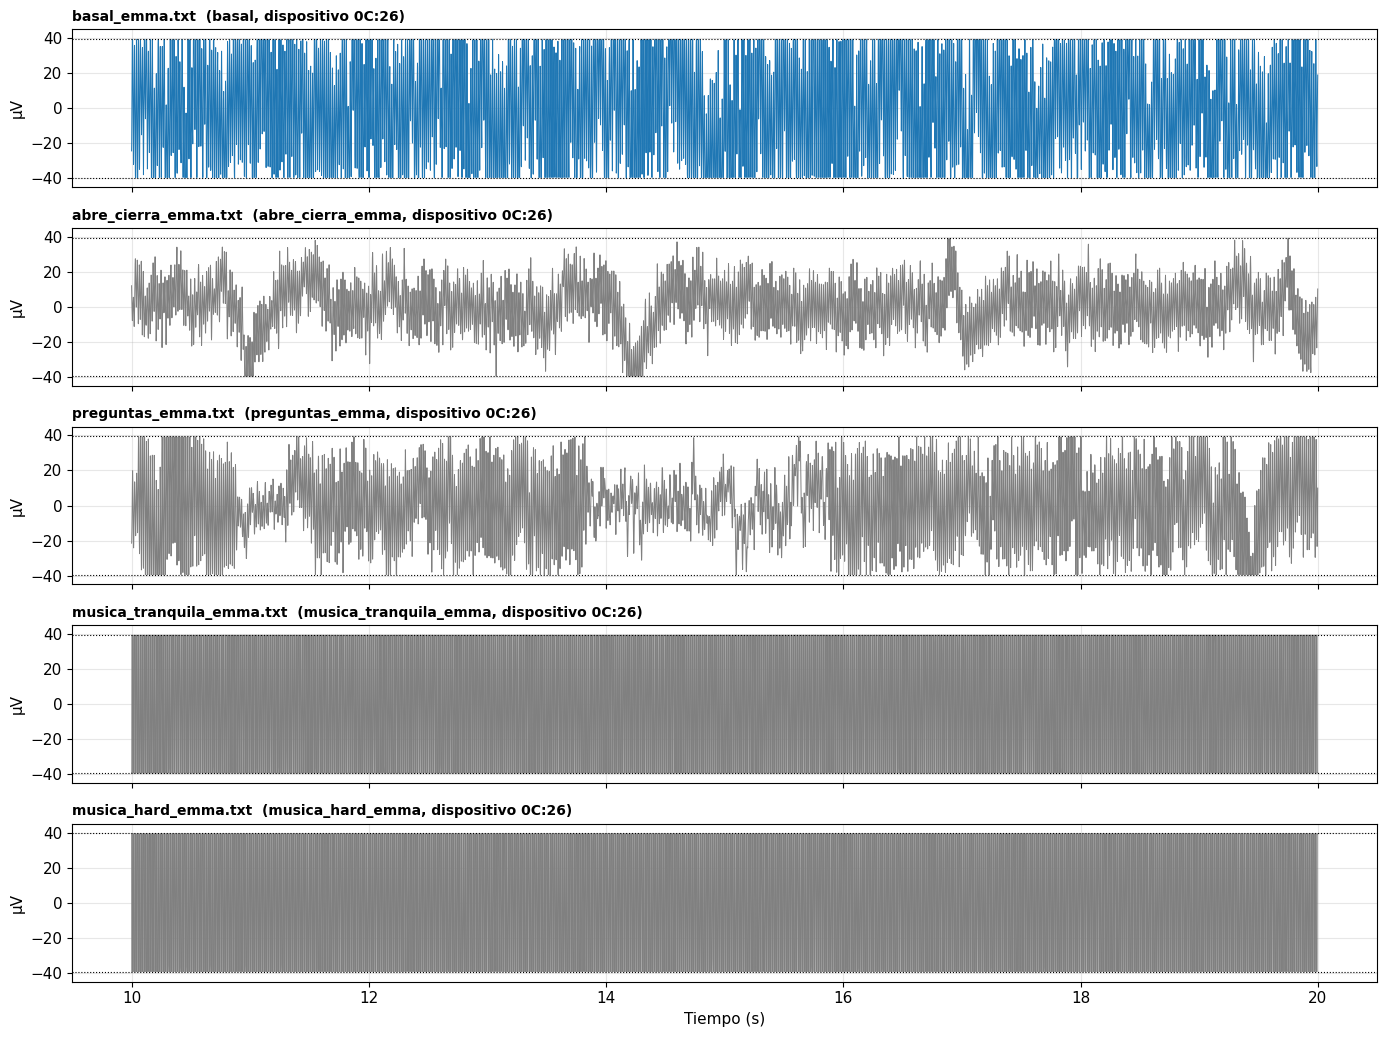

In [ ]:
RANGO_UV = 0.5 * 3.3 / 41782 * 1e6      # ±39.5 µV
T0, DUR = 10, 10
fig, ax = plt.subplots(len(inventario), 1, figsize=(14, 2.1 * len(inventario)), sharex=True, squeeze=False)
for a, (_, fila) in zip(ax[:, 0], tabla_lectura.iterrows()):
    r = senales[fila.archivo]
    t = np.arange(len(r["eeg_uV"])) / FS
    sl = (t >= T0) & (t < T0 + DUR)
    a.plot(t[sl], r["eeg_uV"][sl] - np.mean(r["eeg_uV"]), color=COLOR.get(fila["condición"], "gray"), lw=0.7)
    a.axhline(RANGO_UV, color="k", ls=":", lw=0.8); a.axhline(-RANGO_UV, color="k", ls=":", lw=0.8)
    a.set_ylim(-45, 45); a.set_ylabel("µV")
    a.set_title(f"{fila.archivo}  ({fila['condición']}, dispositivo {fila.dispositivo})", loc="left", fontsize=10)
ax[-1, 0].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

### ✍️ Pregunta A.2
1. ¿Qué registros tienen **mayor amplitud**? ¿Cuáles tocan el rango del sensor?
2. En `parpadeo_masticacion`, ¿distingues ondas lentas grandes (parpadeos) y tramos rápidos (masticación)?

✅ **Respuesta A.2**

1. Ordenados de menor a mayor amplitud:
   - **Basal1:** prácticamente plano, desviación estándar de 1.28 µV.
   - **basal2:** desviación de 2.43 µV.
   - **ojos_abiertos:** desviación de 8.21 µV, inflada por los primeros segundos saturados.
   - **basal3 y música relajante:** oscilaciones de unos ±15–20 µV.
   - **Música estresante:** ondas lentas de hasta ~±25 µV.
   - **parpadeo_masticacion:** el de mayor amplitud (14.17 µV de desviación); **toca repetidamente los límites del sensor** (±39.5 µV).

   Los registros del dispositivo 2A:08 tienen, en general, más amplitud que los del 78:F6.
2. **Sí.** En `parpadeo_masticacion` se ven **ondas lentas y grandes** que llegan al límite del sensor, compatibles con parpadeos. Entre ellas, la señal se ve "peluda", con actividad rápida superpuesta, compatible con la masticación.

<a id="A4"></a>
## A.4 Primer vistazo al espectro: ¿y ese pico en 40 Hz?

Calculamos la **densidad espectral de potencia (PSD)** con el **método de Welch**, tal como en la clase:
1. Dividir la señal en segmentos superpuestos.
2. Aplicar una ventana a cada segmento.
3. Calcular la FFT de cada segmento → periodograma.
4. **Promediar** los periodogramas. Así se obtiene una estimación mucho más estable que con una sola FFT.

### 📖 Aliasing: cuando una frecuencia se "disfraza" de otra
Con **Fs = 100 Hz** solo podemos representar frecuencias hasta **50 Hz** (Nyquist). Una señal de **60 Hz**, como la de la red eléctrica, **no desaparece**: se "pliega" y aparece en otra frecuencia:

$$
f_{alias} = |f - k \cdot F_s| = |60 - 1 \cdot 100| = \mathbf{40\ Hz}
$$

> 💡 **Analogía:** es el efecto de las ruedas de un auto que en un video parecen girar lento o al revés. La cámara toma pocas fotos por segundo y "engaña" sobre la velocidad real.

Si vemos un pico angosto en **40 Hz**, es muy probable que sea **la red eléctrica disfrazada**, no actividad gamma del cerebro.

### 📖 Ritmo cerebral vs. "línea" de interferencia
Un ritmo cerebral (por ejemplo, la alfa) aparece en el espectro como una **"loma" ancha**, de 1 a 3 Hz de ancho, porque su frecuencia fluctúa. Una **interferencia** (red eléctrica, equipos cercanos, la propia electrónica) aparece como una **"línea" muy angosta y muy alta**: ocupa una sola frecuencia y sobresale cientos de veces sobre sus vecinas.

El cuaderno busca automáticamente **líneas angostas**: picos que sobresalen **más de 100 veces** sobre su entorno (con resolución de 0.05 Hz) y que concentran **al menos el 4 %** de la potencia de 1–45 Hz.

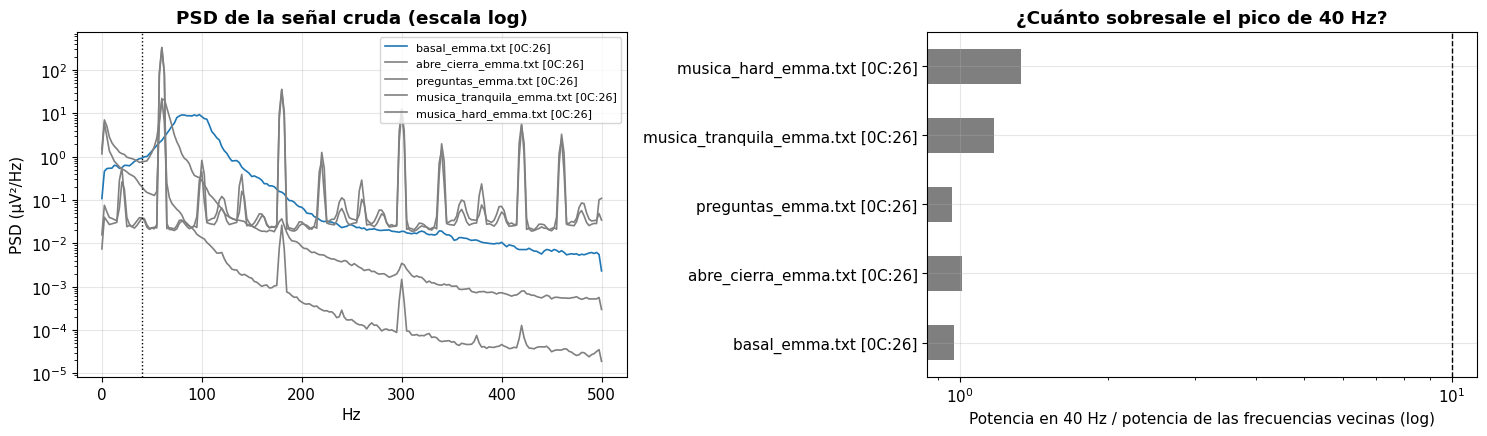

,pico en 40 Hz (veces)
basal_emma.txt [0C:26],1.0
abre_cierra_emma.txt [0C:26],1.0
preguntas_emma.txt [0C:26],1.0
musica_tranquila_emma.txt [0C:26],1.2
musica_hard_emma.txt [0C:26],1.3


,archivo,dispositivo,líneas angostas (Hz → % de la potencia)
0,basal_emma.txt,0C:26,ninguna
1,abre_cierra_emma.txt,0C:26,ninguna
2,preguntas_emma.txt,0C:26,ninguna
3,musica_tranquila_emma.txt,0C:26,20.9 Hz → 8.8 %
4,musica_hard_emma.txt,0C:26,19.0 Hz → 17.0 %


In [ ]:
def psd(x, fs=FS, nperseg=400):
    return signal.welch(x - np.mean(x), fs=fs, nperseg=min(nperseg, len(x)))

def pico_relativo(f, P, f0=40, ancho=2):
    vecinos = P[(np.abs(f - f0) > ancho) & (np.abs(f - f0) < 6)]
    return P[np.argmin(np.abs(f - f0))] / np.median(vecinos)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
dispositivos = tabla_lectura["dispositivo"].unique()
for _, fila in tabla_lectura.iterrows():
    r = senales[fila.archivo]
    f, P = psd(r["eeg_uV"][~r["saturada"]] if r["saturada"].mean() < 0.5 else r["eeg_uV"])
    estilo = "-" if fila.dispositivo == dispositivos[0] else "--"
    ax[0].semilogy(f, P, estilo, color=COLOR.get(fila["condición"], "gray"), lw=1.2, label=f"{fila.archivo} [{fila.dispositivo}]")
    r["pico40"] = pico_relativo(f, P)
ax[0].axvline(40, color="k", ls=":", lw=1)
ax[0].set_xlabel("Hz"); ax[0].set_ylabel("PSD (µV²/Hz)"); ax[0].set_title("PSD de la señal cruda (escala log)")
ax[0].legend(fontsize=8)
picos = pd.Series({f"{a} [{senales[a]['dispositivo']}]": senales[a]["pico40"] for a in tabla_lectura.archivo})
picos.plot.barh(ax=ax[1], color=["tab:gray" if senales[a]["dispositivo"] == dispositivos[0] else "tab:red"
                                 for a in tabla_lectura.archivo], log=True)
ax[1].axvline(10, color="k", ls="--", lw=1)
ax[1].set_xlabel("Potencia en 40 Hz / potencia de las frecuencias vecinas (log)")
ax[1].set_title("¿Cuánto sobresale el pico de 40 Hz?")
plt.tight_layout(); plt.show()
display(picos.round(1).rename("pico en 40 Hz (veces)").to_frame())

def lineas_angostas(x, fs=FS, prominencia_log=2.0, fraccion_min=0.04):
    # Picos espectrales muy angostos (interferencias): >100 veces sobre su entorno y >= 4 % de la potencia
    f, P = signal.welch(x - np.mean(x), fs=fs, nperseg=min(20 * fs, len(x)))
    total = P[(f >= 1) & (f <= 45)].sum()
    picos_idx, props = signal.find_peaks(np.log10(P), prominence=prominencia_log)
    lineas = []
    for p in picos_idx:
        fraccion = P[max(0, p - 2): p + 3].sum() / total
        if 1.5 <= f[p] <= 48 and fraccion >= fraccion_min:
            lineas.append((round(float(f[p]), 2), round(100 * fraccion, 1)))
    return lineas

i_rec = 4 * FS   # se ignoran los primeros 4 s (ver A.6)
filas = []
for a in tabla_lectura.archivo:
    r = senales[a]
    r["lineas_detectadas"] = lineas_angostas(r["eeg_uV"][i_rec:])
    filas.append({"archivo": a, "dispositivo": r["dispositivo"],
                  "líneas angostas (Hz → % de la potencia)": ", ".join(f"{fr} Hz → {pc} %" for fr, pc in r["lineas_detectadas"]) or "ninguna"})
display(pd.DataFrame(filas))

### ✍️ Pregunta A.3
1. ¿Qué archivos tienen un pico grande en 40 Hz? ¿Tienen algo en común (mira el **dispositivo**)?
2. Según la fórmula de aliasing, ¿de dónde viene ese pico? ¿Qué filtro *notch* deberíamos usar: 60 Hz o 40 Hz?
3. ¿Qué **otras líneas angostas** encontró el detector? ¿En qué dispositivo? ¿Caen dentro de alguna banda cerebral? ¿Qué pasaría con la potencia de esa banda si no las quitamos?

✅ **Respuesta A.3**

1. **Pico grande en 40 Hz:** basal3 (403 veces), música relajante (315), música estresante (50) y parpadeo_masticacion (45). **Todos son del dispositivo 2A:08.** Los registros del 78:F6 no lo tienen (0.6–1.7 veces).
2. Por la fórmula de aliasing, $|60 - 100| = 40$ Hz: el pico es la **red eléctrica de 60 Hz**, que aparece en 40 Hz porque se muestreó a 100 Hz. Hay que usar un **notch en 40 Hz**. Un notch en 60 Hz es imposible: 60 Hz está por encima de Nyquist y esa frecuencia ya no existe en la señal muestreada.
3. Las **otras líneas angostas** están solo en el dispositivo **78:F6**:
   - **4.6 Hz:** concentra el **24.0 %** de la potencia de Basal1, el 13.3 % de basal2 y el 12.2 % de ojos_abiertos.
   - **9.15 Hz**, aproximadamente el doble de 4.6 Hz: 6.1 % en ojos_abiertos y 5.9 % en basal2.
   - **25 Hz:** 13.7 % en Basal1.

   Caen en **theta** (4.6 Hz), **alfa** (9.15 Hz) y **beta** (25 Hz). Ocupan una sola frecuencia y sobresalen más de 100 veces, así que **no son ritmos cerebrales**: con estos datos no podemos determinar su origen. Si no se quitan, inflan artificialmente esas bandas. En la Pregunta 3b del cuestionario, la theta de Basal1 pasa de 13.3 % a **33.4 %** si se dejan.

<a id="A5"></a>
## A.5 Control de calidad automático

Resumimos la calidad de cada archivo con un **semáforo**:

| Estado | Criterio |
|---|---|
| ✅ Bueno | Sin saturación, sin pico en 40 Hz (< 10 veces sus vecinos) y sin otras líneas angostas |
| ⚠️ Revisar | Saturación < 1 %, pico de 40 Hz ≥ 10 veces **o** líneas angostas (interferencias que un filtro puede quitar) |
| ❌ Problemático | Saturación ≥ 1 % de las muestras |

También calculamos la **curtosis** de la señal. Una curtosis alta indica **eventos aislados muy grandes** (parpadeos, movimientos, saltos), típicos de artefactos.

In [ ]:
filas = []
for _, fila in tabla_lectura.iterrows():
    r = senales[fila.archivo]
    pct = 100 * r["saturada"].mean()
    otras = [fr for fr, _ in r["lineas_detectadas"] if abs(fr - 40) > 1]
    estado = "❌" if pct >= 1 else ("⚠️" if (pct > 0 or r["pico40"] >= 10 or otras) else "✅")
    x = r["eeg_uV"] - np.mean(r["eeg_uV"])
    filas.append({"archivo": fila.archivo, "condición": fila["condición"], "dispositivo": fila.dispositivo,
                  "% saturado": round(pct, 2), "pico 40 Hz (veces)": round(r["pico40"], 1),
                  "otras líneas (Hz)": ", ".join(map(str, otras)) or "-",
                  "desv. estándar (µV)": round(np.std(x), 2), "curtosis": round(kurtosis(x), 1),
                  "estado": estado})
calidad = pd.DataFrame(filas)
display(calidad)

,archivo,condición,dispositivo,% saturado,pico 40 Hz (veces),otras líneas (Hz),desv. estándar (µV),curtosis,estado
0,basal_emma.txt,basal,0C:26,34.47,1.0,-,29.06,-1.5,❌
1,abre_cierra_emma.txt,abre_cierra_emma,0C:26,0.66,1.0,-,13.16,0.0,⚠️
2,preguntas_emma.txt,preguntas_emma,0C:26,7.44,1.0,-,20.68,-0.8,❌
3,musica_tranquila_emma.txt,musica_tranquila_emma,0C:26,94.44,1.2,20.9,38.49,-2.0,❌
4,musica_hard_emma.txt,musica_hard_emma,0C:26,96.03,1.3,19.0,38.74,-2.0,❌


### ✍️ Pregunta A.4
1. ¿Qué archivos quedaron en ❌ y en ⚠️? ¿Por qué motivo cada uno?
2. ¿Qué archivo tiene la curtosis más alta? Relaciónalo con la columna *segundos con saturación* de A.2.

✅ **Respuesta A.4**

1. **❌ (saturación ≥ 1 %):**
   - `ojos_abiertos` (3.15 %);
   - `parpadeo_masticacion` (2.63 %);
   - `musica_estresante` (1.00 %, justo en el límite).

   **⚠️ (interferencias):**
   - `Basal1` y `basal2`: líneas en 4.6, 9.15 y/o 25 Hz.
   - `basal3`: pico de 40 Hz de 403 veces.
   - `musica_relajante`: pico de 40 Hz de 315 veces y 0.18 % de saturación.

   **Ningún archivo queda en ✅.**
2. **`ojos_abiertos` tiene la curtosis más alta (15.5).** No se debe a los ojos abiertos, sino a que **toda su saturación ocurre en los primeros 3 s**: unos pocos valores extremos al inicio elevan mucho la curtosis. Por eso se decidió recortar los primeros 4 s de cada registro.

<a id="A6"></a>
## A.6 Conclusiones de la Parte A: decisiones para el procesamiento

La revisión de los datos nos lleva a **cuatro decisiones** que aplicaremos en la Parte B. Ajústalas si tus datos lo requieren:

| Parámetro | Valor por defecto | ¿Por qué? |
|---|---|---|
| `RECORTE_INICIO_S` | 4 s | Al iniciar la adquisición, el amplificador tarda unos segundos en estabilizarse |
| `NOTCH_HZ` | 40 Hz | Es el **alias** de la red eléctrica de 60 Hz cuando Fs = 100 Hz |
| `QUITAR_LINEAS` | `True` | Aplica un notch angosto en cada **línea de interferencia** detectada en A.4, en su propio archivo |
| Rechazo de épocas | Toda época con al menos una muestra saturada | La saturación destruye información que ningún filtro puede recuperar |

### ✍️ Pregunta A.5
Escribe en 3 a 4 líneas tus conclusiones sobre la calidad de tus datos. ¿Hay algún archivo que no usarías? ¿Por qué podría ser un problema que se hayan usado **dos dispositivos distintos**?

✅ **Respuesta A.5 — Conclusiones de la Parte A**

Ningún registro es perfecto, pero todos son **utilizables** con tres medidas:
- **Recortar los primeros 4 s:** elimina toda la saturación de ojos_abiertos.
- **Filtrar las interferencias:** notch en 40 Hz y en las líneas angostas detectadas.
- **Rechazar las épocas saturadas:** afecta sobre todo a parpadeo_masticacion.

**El problema de los dos dispositivos.** Las condiciones no están repartidas entre ambos equipos:
- **ojos_abiertos** solo se grabó con 78:F6.
- **Parpadeo y las dos músicas** solo con 2A:08.
- **Basal** está en ambos.

Además, cada equipo deja su propia "huella": interferencia de 40 Hz en uno, líneas de 4.6 y 25 Hz en el otro, y distinta amplitud. Por eso, cualquier diferencia entre condiciones de distinto equipo puede deberse **al equipo y no al cerebro**. Es una **variable de confusión**, y en B.8 se comprueba que es real.

In [ ]:
# =================== ✍️ DECISIONES (puedes modificarlas) ===================
RECORTE_INICIO_S = 4      # segundos que se descartan al inicio de cada registro
NOTCH_HZ = 40             # 40 = alias de 60 Hz con Fs = 100 Hz; None = sin notch
QUITAR_LINEAS = True      # notch angosto en las líneas de interferencia detectadas en A.4
# ==========================================================================
print(f"Recorte inicial: {RECORTE_INICIO_S} s | Notch: {NOTCH_HZ} Hz | Quitar líneas angostas: {QUITAR_LINEAS}")

Recorte inicial: 4 s | Notch: 40 Hz | Quitar líneas angostas: True


---
<a id="parteB"></a>
# 🅱️ PARTE B — Tratamiento y extracción de características *(≈ 40 min)*

[⬆️ Volver al índice](#indice)

<a id="B1"></a>
## B.1 El pipeline de procesamiento

Este es el camino que recorrerá cada registro, siguiendo el esquema de la clase:

| Paso | Etapa | Qué hace | Sección |
|---|---|---|---|
| 1 | **Filtrado** | Quita la deriva lenta, el ruido de alta frecuencia y la red eléctrica (40 Hz) | B.2 |
| 2 | **Análisis de ritmos** | Mide cuánta potencia hay en delta, theta, alfa, beta y gamma | B.3 |
| 3 | **Limpieza con ICA** | Separa y elimina componentes de artefactos (parpadeos, interferencia) | B.4 |
| 4 | **Preprocesamiento** | Normalización (z-score) y corte en épocas de 2 s; se rechazan las saturadas | B.5 |
| 5 | **Extracción de características** | ~22 números por época | B.6 |
| 6 | **Ingeniería de características** | Cocientes entre bandas, logaritmos, tabla final | B.6–B.7 |
| 7 | **Clasificación** | ¿Podemos reconocer la condición a partir de las características? | B.8 |

<a id="B2"></a>
## B.2 Filtrado

| Filtro | Configuración | ¿Por qué? |
|---|---|---|
| **Pasa-banda Butterworth** | 1 – 45 Hz, orden 4 | Quita la deriva lenta (< 1 Hz) y se queda por debajo de Nyquist (50 Hz). El ejemplo de MNE también recomienda un pasa-altos de 1 Hz antes de aplicar ICA |
| **Notch** | 40 Hz (Q = 20) | Elimina el **alias de la red eléctrica** encontrado en A.4 |
| **Notch angostos** | En cada línea detectada en A.4 (Q = 30, ~0.15–0.8 Hz de ancho) | Elimina las otras interferencias sin borrar la banda cerebral donde caen |

Se filtra "ida y vuelta" (`filtfilt`) para no desfasar la señal. Veamos el efecto en el archivo con **más interferencia**.

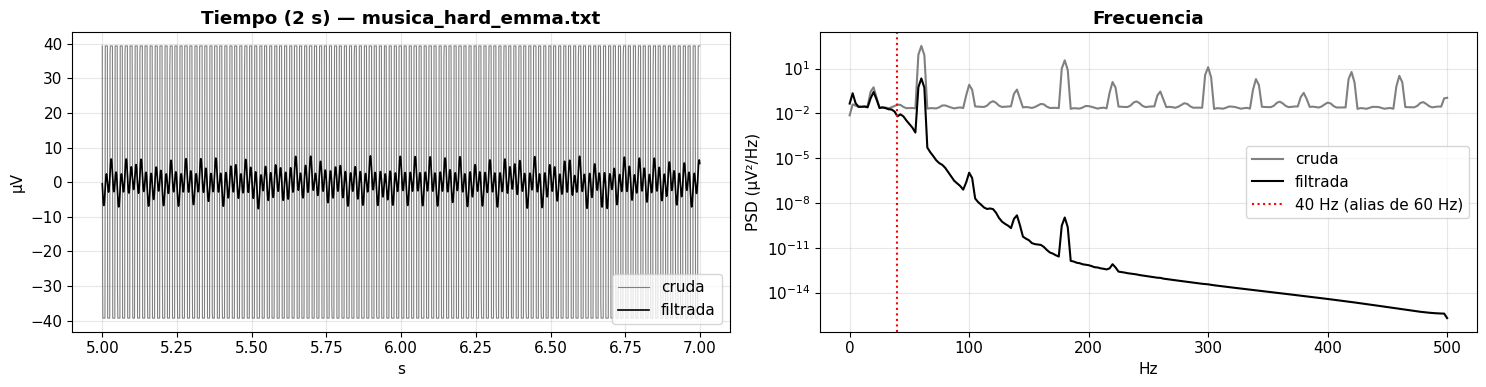

In [ ]:
def filtrar_eeg(x, fs=FS, notch=NOTCH_HZ, lineas=()):
    sos = signal.butter(4, [1, 45], btype="bandpass", fs=fs, output="sos")
    y = signal.sosfiltfilt(sos, x - np.mean(x))
    if notch and notch < fs / 2:
        b, a = signal.iirnotch(notch, 20, fs=fs)
        y = signal.filtfilt(b, a, y)
    elif notch:
        print(f"⚠️ Notch de {notch} Hz imposible: está por encima de Nyquist ({fs/2:.0f} Hz). No se aplicó.")
    for f0 in lineas:                       # notch angosto en cada línea de interferencia
        if notch is None or abs(f0 - notch) > 1:
            b, a = signal.iirnotch(f0, 30, fs=fs)
            y = signal.filtfilt(b, a, y)
    return y

def lineas_de(archivo, quitar=QUITAR_LINEAS):
    return [fr for fr, _ in senales[archivo]["lineas_detectadas"]] if quitar else []

i0 = int(RECORTE_INICIO_S * FS)
peor = max(senales, key=lambda a: senales[a]["pico40"])
x_crudo = senales[peor]["eeg_uV"][i0:] - np.mean(senales[peor]["eeg_uV"][i0:])
x_filt = filtrar_eeg(senales[peor]["eeg_uV"][i0:], lineas=lineas_de(peor))
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
t = np.arange(len(x_crudo)) / FS
sl = (t >= 5) & (t < 7)
ax[0].plot(t[sl], x_crudo[sl], color="gray", lw=0.8, label="cruda")
ax[0].plot(t[sl], x_filt[sl], color="black", lw=1.2, label="filtrada")
ax[0].set_title(f"Tiempo (2 s) — {peor}"); ax[0].set_xlabel("s"); ax[0].set_ylabel("µV"); ax[0].legend()
for s, nom, col in [(x_crudo, "cruda", "gray"), (x_filt, "filtrada", "black")]:
    f, P = psd(s); ax[1].semilogy(f, P, color=col, label=nom)
ax[1].axvline(40, color="r", ls=":", label="40 Hz (alias de 60 Hz)")
ax[1].set_xlabel("Hz"); ax[1].set_ylabel("PSD (µV²/Hz)"); ax[1].set_title("Frecuencia"); ax[1].legend()
plt.tight_layout(); plt.show()

### 🔎 Observa
- **En la frecuencia:** el pico de 40 Hz desaparece y la potencia por debajo de 1 Hz cae. Entre 1 y 38 Hz las curvas casi coinciden.
- **En el tiempo:** la señal cruda tiene una oscilación rápida superpuesta (la interferencia); la filtrada queda más limpia.

<a id="B3"></a>
## B.3 Ritmos cerebrales: delta, theta, alfa, beta y gamma

### 📖 Dos formas de "ver" las bandas
1. **En el tiempo:** filtramos la señal en cada banda y vemos cómo oscila cada "sección de la orquesta".
2. **En la frecuencia:** integramos la PSD de Welch dentro de cada banda para obtener la **potencia de banda**:
   - **Absoluta** (µV²): cuánta energía hay en la banda.
   - **Relativa** (%): qué fracción del total (1–45 Hz) corresponde a esa banda. Es más fácil de comparar entre registros y dispositivos.

> ⚠️ **Gamma en estos datos:** con Fs = 100 Hz solo vemos gamma entre 30 y 45 Hz, y el notch quita 38–42 Hz. La gamma de superficie, además, suele estar dominada por **actividad muscular**. Hay que interpretarla con mucha cautela.

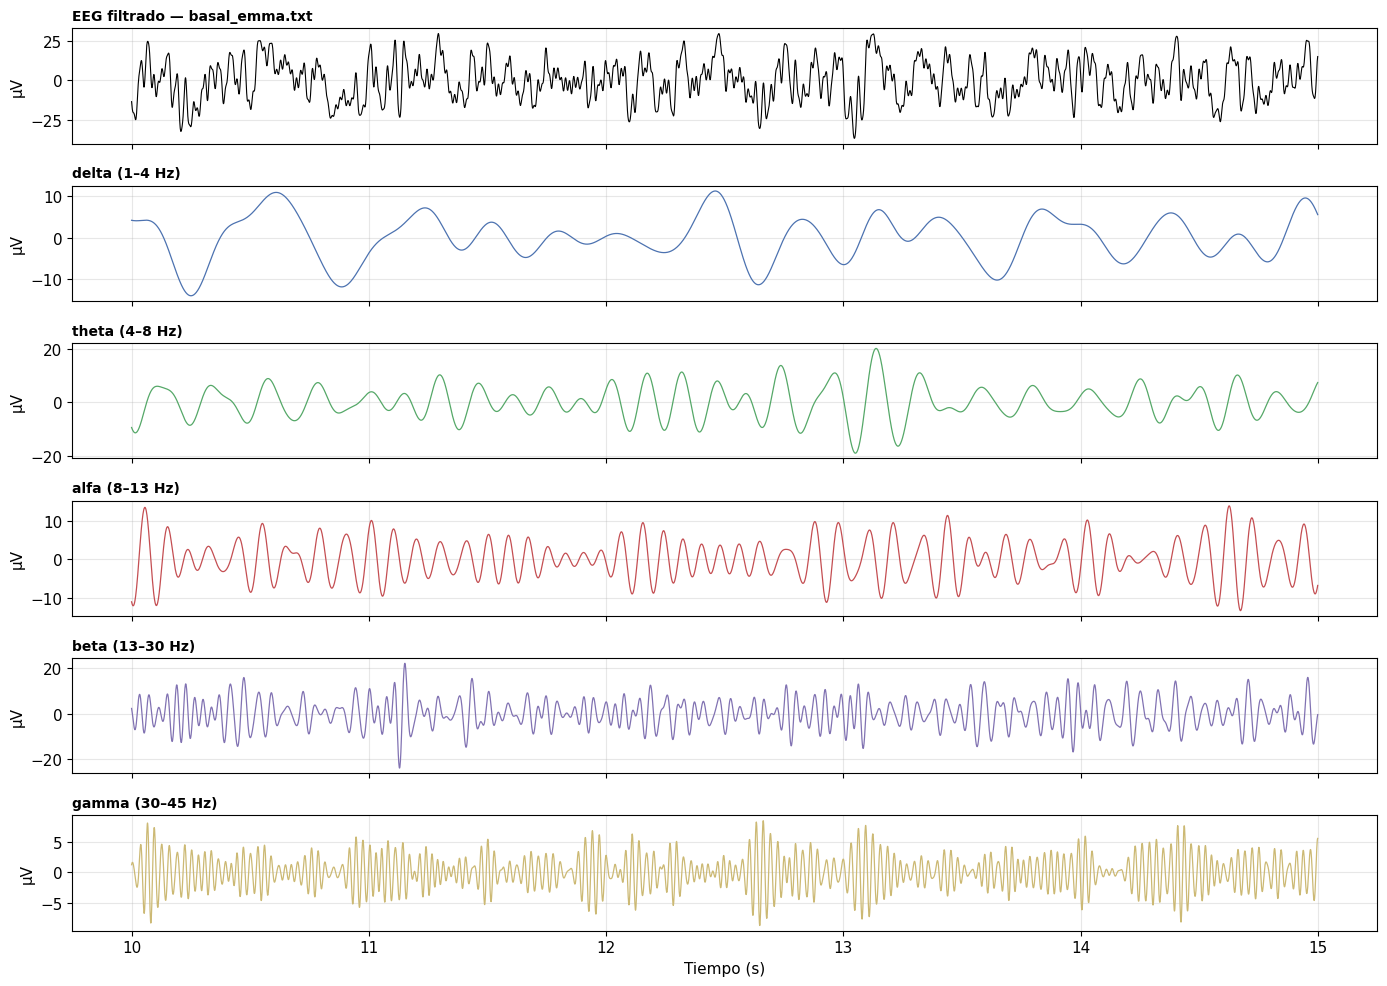

In [ ]:
for a, r in senales.items():
    r["filtrada"] = filtrar_eeg(r["eeg_uV"][i0:], lineas=lineas_de(a))
    r["sat_rec"] = r["saturada"][i0:]

# 1) Bandas en el tiempo para el registro basal más limpio
basales = [a for a in calidad[calidad["condición"] == "basal"].sort_values("pico 40 Hz (veces)").archivo]
ref = basales[0] if basales else list(senales)[0]
x = senales[ref]["filtrada"]; t = np.arange(len(x)) / FS; sl = (t >= 10) & (t < 15)
fig, ax = plt.subplots(6, 1, figsize=(14, 10), sharex=True)
ax[0].plot(t[sl], x[sl], color="black", lw=0.8); ax[0].set_title(f"EEG filtrado — {ref}", loc="left", fontsize=10)
for a, (b, (lo, hi)) in zip(ax[1:], BANDAS.items()):
    sos = signal.butter(4, [lo, hi], btype="bandpass", fs=FS, output="sos")
    a.plot(t[sl], signal.sosfiltfilt(sos, x)[sl], color=COLOR_BANDA[b], lw=0.9)
    a.set_title(f"{b} ({lo}–{hi} Hz)", loc="left", fontsize=10)
for a in ax: a.set_ylabel("µV")
ax[-1].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

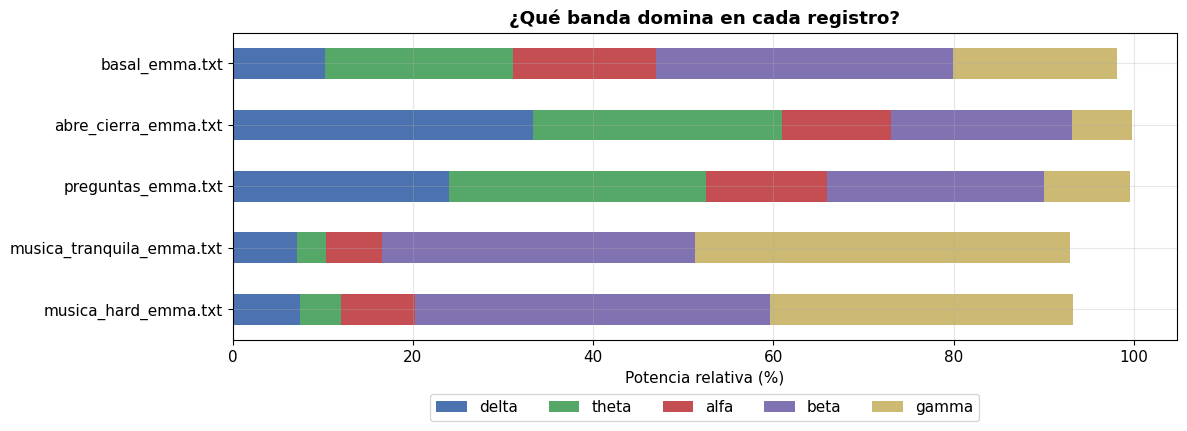

,delta,theta,alfa,beta,gamma
basal_emma.txt,10.2,20.9,15.9,32.9,18.3
abre_cierra_emma.txt,33.3,27.6,12.1,20.1,6.7
preguntas_emma.txt,24.0,28.5,13.4,24.1,9.6
musica_tranquila_emma.txt,7.1,3.3,6.2,34.7,41.6
musica_hard_emma.txt,7.5,4.5,8.2,39.4,33.6


In [ ]:
# 2) Potencia relativa por banda en cada registro (PSD de Welch sobre la señal filtrada, sin muestras saturadas)
def potencia_bandas(x, fs=FS):
    f, P = signal.welch(x - np.mean(x), fs=fs, nperseg=min(400, len(x)))
    total = P[(f >= 1) & (f <= 45)].sum()
    return {b: P[(f >= lo) & (f < hi)].sum() / total for b, (lo, hi) in BANDAS.items()}

pot = pd.DataFrame({a: potencia_bandas(r["filtrada"][~r["sat_rec"]]) for a, r in senales.items()}).T * 100
pot = pot.loc[tabla_lectura.archivo]
ax = pot.plot.barh(stacked=True, figsize=(12, 4.5), color=[COLOR_BANDA[b] for b in BANDAS])
ax.set_xlabel("Potencia relativa (%)"); ax.set_title("¿Qué banda domina en cada registro?"); ax.invert_yaxis()
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15)); plt.tight_layout(); plt.show()
display(pot.round(1))

### ✍️ Pregunta B.1
1. ¿Qué banda domina en los registros **basales** (ojos cerrados)? ¿Es la alfa, como se esperaría?
2. Compara `Basal1` con `ojos_abiertos`. ¿Disminuye la alfa al abrir los ojos? ¿Qué banda cambia más?
3. *(Para pensar)* Los electrodos están en **Fp1/Fp2** (frente). La alfa de reposo es más fuerte en la zona **occipital** (nuca). ¿Cómo influye esto en lo que ves?

✅ **Respuesta B.1** (potencia relativa de cada registro, tras quitar las interferencias)

1. **La alfa no domina** en ningún registro basal:
   - **Basal1:** delta 29.9 %, beta 26.9 %, gamma 18.7 %, theta 13.3 %, alfa 11.0 %.
   - **basal2:** domina beta (47.0 %).
   - **basal3:** domina delta (38.0 %).

   La alfa queda entre 11 % y 17 % en los tres. No se observa el patrón clásico de "alfa dominante con ojos cerrados".
2. **No disminuye.** La alfa de ojos_abiertos (13.4 %) es incluso algo mayor que la de Basal1 (11.0 %) e igual a la de basal2 (13.4 %): **no se observa el bloqueo alfa**. Lo que más cambia entre Basal1 y ojos_abiertos es la **delta**, que baja de 29.9 % a 7.4 %, y la **beta**, que sube de 26.9 % a 43.1 %. Más beta con ojos abiertos es compatible con un mayor estado de alerta.
3. *(Conceptual)* La alfa de reposo se genera sobre todo en la corteza **occipital y parietal**. Un electrodo bipolar entre **Fp1 y Fp2** (frente) está lejos de esa zona y, además, resta dos puntos casi simétricos, lo que atenúa la actividad común a ambos. Por eso la alfa se ve poco, y la región frontal es más sensible a los movimientos oculares y a los músculos de la frente.

<a id="B4"></a>
## B.4 Filtro ICA: separar el cerebro de los artefactos

### B.4.1 📖 Definición fácil: el problema de la fiesta (*cocktail party*)
Imagina una fiesta con **3 personas hablando** y **3 micrófonos** en distintos lugares. Cada micrófono graba una **mezcla** de las tres voces. El **Análisis de Componentes Independientes (ICA)** es un algoritmo que, solo con las grabaciones de los micrófonos, **recupera cada voz por separado**.

En el EEG:
- Los **micrófonos** son los electrodos.
- Las **voces** son las fuentes: actividad cerebral, parpadeos, músculos, red eléctrica.

Si separamos las fuentes, podemos **apagar las de artefactos** y reconstruir una señal limpia.

### En términos matemáticos

$$
\underbrace{\mathbf{X}}_{\text{electrodos}} = \underbrace{\mathbf{A}}_{\text{mezcla}} \cdot \underbrace{\mathbf{S}}_{\text{fuentes}}
\qquad\Longrightarrow\qquad
\hat{\mathbf{S}} = \mathbf{W}\,\mathbf{X}, \quad \mathbf{W} \approx \mathbf{A}^{-1}
$$

ICA estima la matriz de "desmezcla" **W** suponiendo que:
1. Las fuentes son **estadísticamente independientes**.
2. Las fuentes **no son gaussianas**. El algoritmo FastICA busca justamente las direcciones más "no gaussianas".
3. Hay **al menos tantos canales como fuentes** que queremos separar.

**Limpieza en 3 pasos:** (1) descomponer en componentes; (2) **identificar** las de artefactos; (3) ponerlas en cero y **reconstruir**.

### B.4.2 Demostración con señales simuladas
Antes de usar datos reales, probamos ICA en un caso donde **conocemos la respuesta**: 3 fuentes (alfa de 10 Hz, parpadeos y ráfagas musculares) mezcladas en 3 "electrodos".

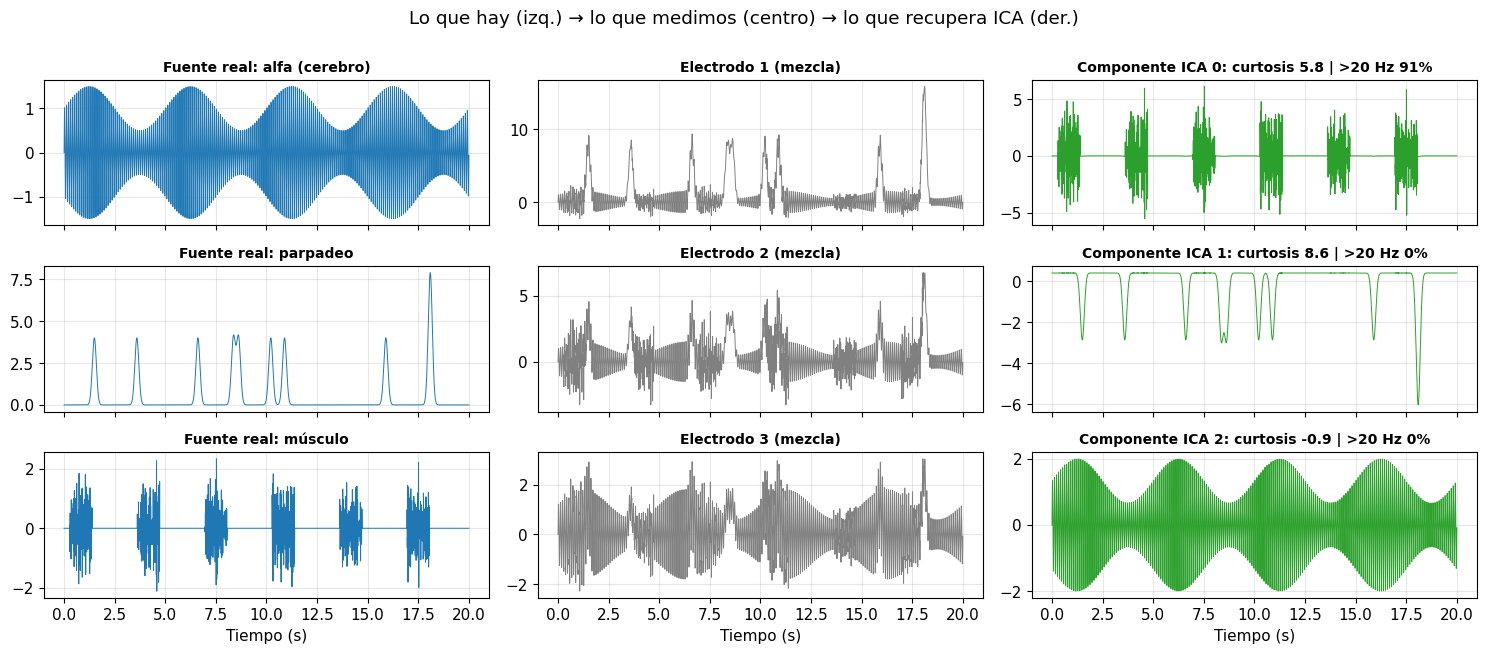

In [ ]:
rng = np.random.default_rng(1)
ts = np.arange(0, 20, 1/FS)
alfa = np.sin(2*np.pi*10*ts) * (1 + 0.5*np.sin(2*np.pi*0.2*ts))                 # fuente cerebral
parpadeo = sum(np.exp(-((ts - tp)**2) / (2*0.1**2)) for tp in rng.uniform(1, 19, 10)) * 4  # fuente ocular
b, a_ = signal.butter(4, [20, 45], "bandpass", fs=FS)
musculo = (np.sin(2*np.pi*0.3*ts) > 0.5) * signal.lfilter(b, a_, rng.standard_normal(len(ts))) * 3  # fuente muscular
S_real = np.c_[alfa, parpadeo, musculo]
A_mezcla = np.array([[1.0, 2.0, 0.6],     # electrodo 1 (frontal: mucho parpadeo)
                     [1.0, 0.8, 1.2],     # electrodo 2
                     [1.2, 0.3, 0.4]])    # electrodo 3
X = S_real @ A_mezcla.T

ica_demo = FastICA(n_components=3, whiten="unit-variance", random_state=0)
S_est = ica_demo.fit_transform(X)

def metricas_componente(s, fs=FS):
    f, P = signal.welch(s, fs=fs, nperseg=min(256, len(s)))
    tot = P[f >= 1].sum()
    return {"curtosis": kurtosis(s), "fracción > 20 Hz": P[f >= 20].sum() / tot,
            "fracción 38–42 Hz": P[(f >= 38) & (f <= 42)].sum() / tot}

fig, ax = plt.subplots(3, 3, figsize=(15, 6.5), sharex=True)
nombres = ["alfa (cerebro)", "parpadeo", "músculo"]
for k in range(3):
    ax[k, 0].plot(ts, S_real[:, k], lw=0.7); ax[k, 0].set_title(f"Fuente real: {nombres[k]}", fontsize=10)
    ax[k, 1].plot(ts, X[:, k], lw=0.7, color="gray"); ax[k, 1].set_title(f"Electrodo {k+1} (mezcla)", fontsize=10)
    m = metricas_componente(S_est[:, k])
    ax[k, 2].plot(ts, S_est[:, k], lw=0.7, color="tab:green")
    ax[k, 2].set_title(f"Componente ICA {k}: curtosis {m['curtosis']:.1f} | >20 Hz {m['fracción > 20 Hz']:.0%}", fontsize=10)
for a in ax[-1]: a.set_xlabel("Tiempo (s)")
plt.suptitle("Lo que hay (izq.) → lo que medimos (centro) → lo que recupera ICA (der.)", y=1.0)
plt.tight_layout(); plt.show()

### 🔎 Observa
- ICA recupera las tres fuentes a partir de las mezclas. El **orden** y el **signo** pueden cambiar: ICA no sabe cuál es cuál.
- Para **identificar** cada componente usamos dos métricas sencillas:
  - **Curtosis alta** → eventos aislados y grandes, como **parpadeos** o movimientos.
  - **Mucha potencia por encima de 20 Hz** → actividad **muscular**.

### B.4.3 ¿Cómo se hace en EEG multicanal? El ejemplo de MNE
El ejemplo [*Removing muscle ICA components*](https://mne.tools/stable/auto_examples/preprocessing/muscle_ica.html) de **MNE-Python** aplica ICA a un EEG de 59 canales:
1. Aplica un **pasa-altos de 1 Hz** ("ICA funciona mejor con un pasa-altos").
2. Ajusta un ICA de **15 componentes**.
3. Marca como **musculares** las componentes que cumplen los criterios de Dharmaprani et al. (2016):
   - **pendiente positiva** del espectro en escala log-log entre 7 y 75 Hz;
   - foco **periférico** en el mapa topográfico (lejos del vértex);
   - **un solo foco**, poco "suave" espacialmente;
   - y, además, una serie temporal "peluda", con picos como de EMG.
4. Compara la selección manual con la automática `ica.find_bads_muscle(raw)`.

```python
# Esquema del ejemplo de MNE (EEG multicanal; no se ejecuta en este cuaderno)
import mne
raw.filter(l_freq=1.0, h_freq=None)
ica = mne.preprocessing.ICA(n_components=15, method="picard", max_iter="auto", rng=97)
ica.fit(raw)
muscle_idx_auto, scores = ica.find_bads_muscle(raw)
ica.apply(raw, exclude=muscle_idx_auto)
```

> ⚠️ **Nuestro problema:** BITalino nos da **un solo canal**, e ICA necesita **al menos tantos canales como fuentes**. Además, sin varios electrodos no hay mapa topográfico, así que solo podemos usar los criterios **temporales y espectrales**.

### B.4.4 Solución para un canal: Wavelet-ICA
Una técnica usada en la literatura (Castellanos y Makarov, 2006) consiste en **fabricar "canales virtuales"** a partir del único canal:

1. Se descompone la señal con la **transformada wavelet** en **6 sub-bandas**. Es un análisis multirresolución: las sub-bandas **sumadas devuelven exactamente la señal original**.
2. Esas 6 sub-bandas se tratan como si fueran **6 electrodos**, y se aplica **FastICA**.
3. Se revisa cada componente:
   - **Más del 40 % de su potencia en 38–42 Hz** → es **interferencia de red** (alias). Se **elimina entera**. Solo aparece si no se usó el notch.
   - **Curtosis > 6** → contiene **transitorios** (parpadeos bruscos, movimientos, saltos). Se **corrige**: con una transformada wavelet se anulan solo los coeficientes **atípicamente grandes** (más de 4 desviaciones robustas). Es la idea del método WICA.
   - El resto se **conserva**.
4. Se vuelve a las sub-bandas y se **suman** para obtener la señal limpia.

> 💡 **¿Por qué corregir y no borrar?** En el EEG multicanal de MNE, una componente muscular es casi "pura" y se borra entera. Con un solo canal, cada componente mezcla un poco de cerebro y un poco de artefacto: si la borráramos entera, nos llevaríamos también una banda completa del EEG. Por eso solo "recortamos" la parte anómala.

Con Fs = 100 Hz y 6 niveles, las sub-bandas son aproximadamente:

| Sub-banda | Rango | Ritmo cercano |
|---|---|---|
| D1 | 25 – 50 Hz | gamma / beta alta |
| D2 | 12.5 – 25 Hz | beta |
| D3 | 6.25 – 12.5 Hz | alfa / theta alta |
| D4 | 3.1 – 6.25 Hz | theta |
| D5 | 1.6 – 3.1 Hz | delta |
| A5 | 0 – 1.6 Hz | muy lento (parpadeos, deriva) |

In [ ]:
KURT_UMBRAL = 6       # curtosis por encima de la cual una componente contiene transitorios (artefactos)
LINEA_UMBRAL = 0.4    # fracción de potencia en 38–42 Hz por encima de la cual es interferencia de red
K_UMBRAL = 4          # umbral para "recortar" transitorios: coeficientes > K · desviación robusta
NOMBRES_SUBBANDA = ["D1 (25–50 Hz)", "D2 (12.5–25)", "D3 (6.25–12.5)", "D4 (3.1–6.25)", "D5 (1.6–3.1)", "A5 (0–1.6)"]

def subbandas_wavelet(x, nivel=5, wavelet="sym4"):
    # Análisis multirresolución (SWT): devuelve sub-bandas que SUMADAS reconstruyen x exactamente
    n = len(x); m = int(np.ceil(n / 2**nivel) * 2**nivel)
    xp = np.pad(x, (0, m - n), mode="reflect")
    comp = np.array(pywt.mra(xp, wavelet, level=nivel, transform="swt"))[:, :n]
    return comp[::-1]      # orden: D1 (rápida) ... A5 (lenta)

def quitar_transitorios(s, k=K_UMBRAL, wavelet="db4", nivel=4):
    # Corrección tipo WICA: en cada nivel wavelet se anulan SOLO los coeficientes atípicamente grandes
    coef = pywt.wavedec(s, wavelet, level=nivel)
    coef = [c * (np.abs(c) <= k * np.median(np.abs(c)) / 0.6745) for c in coef]
    return pywt.waverec(coef, wavelet)[:len(s)]

def ica_un_canal(x, kurt_umbral=KURT_UMBRAL, linea_umbral=LINEA_UMBRAL):
    V = subbandas_wavelet(x)                                     # (6, n): "canales virtuales"
    ica = FastICA(n_components=V.shape[0], whiten="unit-variance", random_state=0, max_iter=3000)
    S = ica.fit_transform(V.T)                                   # (n, 6): componentes independientes
    metr = pd.DataFrame([metricas_componente(S[:, k]) for k in range(S.shape[1])])
    aporte = [np.var(np.outer(S[:, k], ica.mixing_[:, k]).sum(axis=1)) / np.var(x) for k in range(S.shape[1])]
    metr["% varianza de la señal"] = 100 * np.array(aporte)
    metr["sub-banda dominante"] = [NOMBRES_SUBBANDA[j] for j in np.argmax(ica.mixing_**2, axis=0)]
    es_red = metr["fracción 38–42 Hz"] > linea_umbral
    es_trans = (metr["curtosis"] > kurt_umbral) & ~es_red
    metr["acción"] = np.where(es_red, "eliminar (red)", np.where(es_trans, "corregir (transitorios)", "conservar"))
    metr["artefacto"] = es_red | es_trans
    S_limpio = S.copy()
    for k in range(S.shape[1]):
        if es_red[k]:
            S_limpio[:, k] = 0                                   # componente de red: se elimina entera
        elif es_trans[k]:
            S_limpio[:, k] = quitar_transitorios(S[:, k])        # componente con transitorios: se corrige
    # Artefacto estimado = lo que se quitó, devuelto a sub-bandas y sumado
    artefacto = (ica.inverse_transform(S) - ica.inverse_transform(S_limpio)).sum(axis=1)
    sos = signal.butter(4, [1, 45], btype="bandpass", fs=FS, output="sos")
    x_limpia = x - signal.sosfiltfilt(sos, artefacto)            # se resta solo dentro de la banda 1–45 Hz
    return x_limpia, {"V": V, "S": S, "S_limpio": S_limpio, "metricas": metr}
print("✅ Funciones de Wavelet-ICA listas.")

✅ Funciones de Wavelet-ICA listas.


### B.4.5 Wavelet-ICA paso a paso sobre el registro con artefactos
Aplicamos el método al registro de **parpadeo y masticación**, que contiene artefactos a propósito.

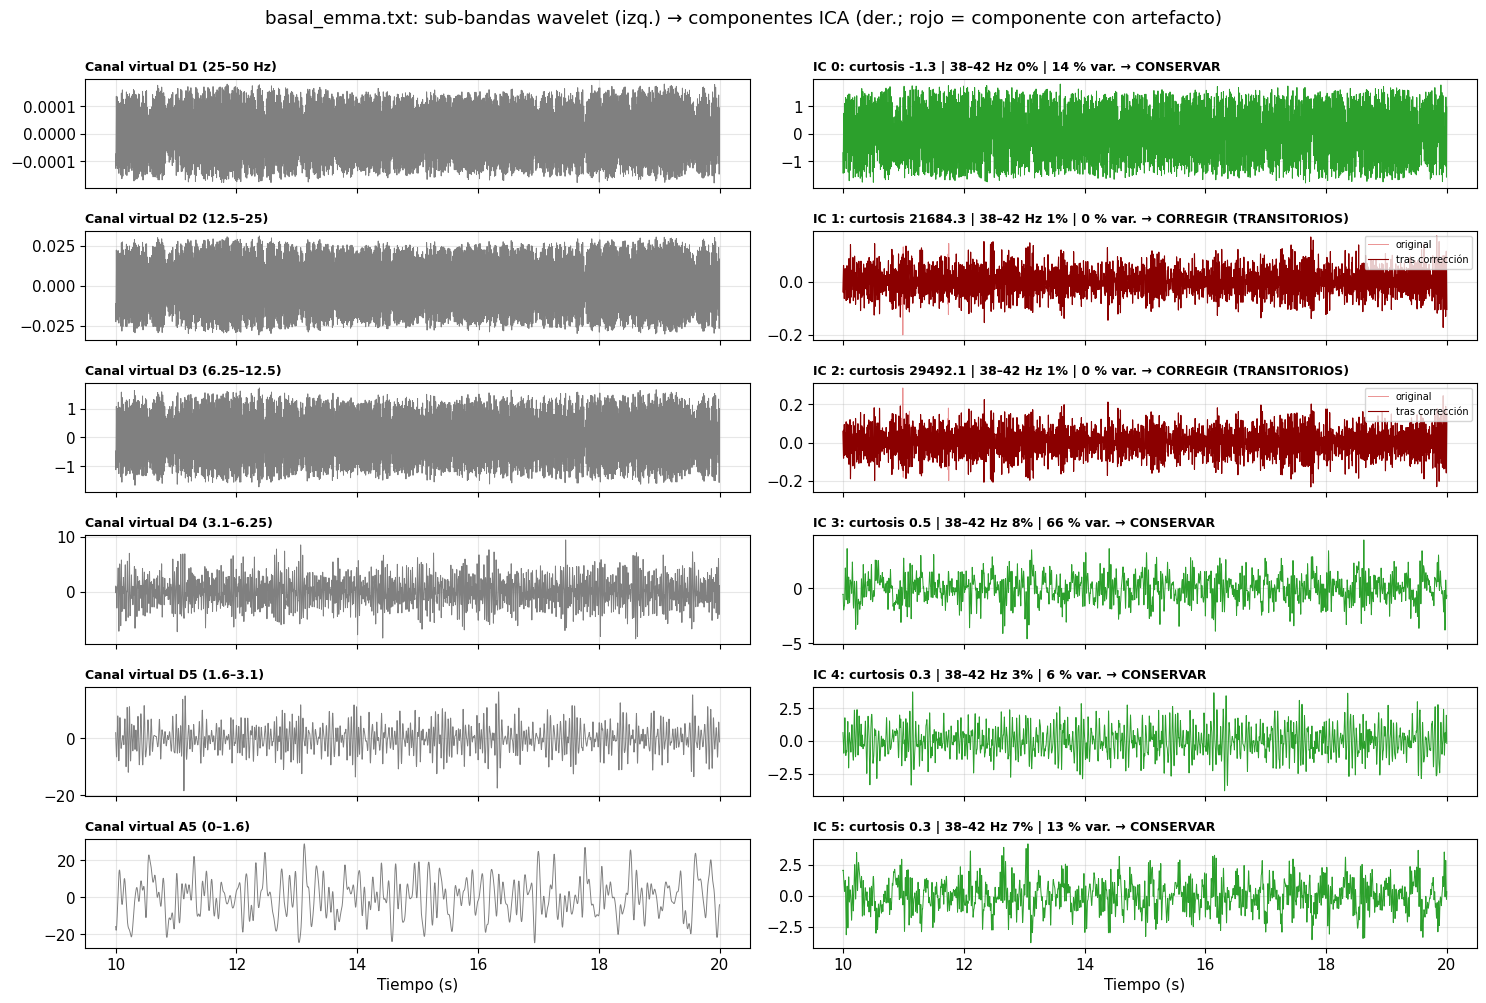

,curtosis,fracción > 20 Hz,fracción 38–42 Hz,% varianza de la señal,sub-banda dominante,acción,artefacto
0,-1.298,0.979,0.001,14.428,D4 (3.1–6.25),conservar,False
1,21684.260,0.951,0.014,0.000,D1 (25–50 Hz),corregir (transitorios),True
2,29492.144,0.919,0.014,0.000,A5 (0–1.6),corregir (transitorios),True
3,0.497,0.619,0.076,66.334,A5 (0–1.6),conservar,False
4,0.250,0.458,0.026,5.905,D5 (1.6–3.1),conservar,False
5,0.255,0.505,0.073,13.332,A5 (0–1.6),conservar,False


In [ ]:
cand = [a for a in senales if condicion_desde_nombre(a) == "parpadeo_masticacion"]
ej = cand[0] if cand else list(senales)[0]
x = senales[ej]["filtrada"]
x_limpia, det = ica_un_canal(x)
t = np.arange(len(x)) / FS; sl = (t >= 10) & (t < 20)

fig, ax = plt.subplots(6, 2, figsize=(15, 10), sharex=True)
for k in range(6):
    ax[k, 0].plot(t[sl], det["V"][k][sl], color="gray", lw=0.7)
    ax[k, 0].set_title(f"Canal virtual {NOMBRES_SUBBANDA[k]}", loc="left", fontsize=9)
    m = det["metricas"].iloc[k]
    if m["artefacto"]:
        ax[k, 1].plot(t[sl], det["S"][sl, k], color="tab:red", lw=0.7, alpha=0.5, label="original")
        ax[k, 1].plot(t[sl], det["S_limpio"][sl, k], color="darkred", lw=0.8, label="tras corrección")
        ax[k, 1].legend(loc="upper right", fontsize=7)
    else:
        ax[k, 1].plot(t[sl], det["S"][sl, k], color="tab:green", lw=0.7)
    ax[k, 1].set_title(f"IC {k}: curtosis {m['curtosis']:.1f} | 38–42 Hz {m['fracción 38–42 Hz']:.0%} | "
                       f"{m['% varianza de la señal']:.0f} % var. → {m['acción'].upper()}", loc="left", fontsize=9)
ax[-1, 0].set_xlabel("Tiempo (s)"); ax[-1, 1].set_xlabel("Tiempo (s)")
plt.suptitle(f"{ej}: sub-bandas wavelet (izq.) → componentes ICA (der.; rojo = componente con artefacto)", y=1.0)
plt.tight_layout(); plt.show()
display(det["metricas"].round(3))

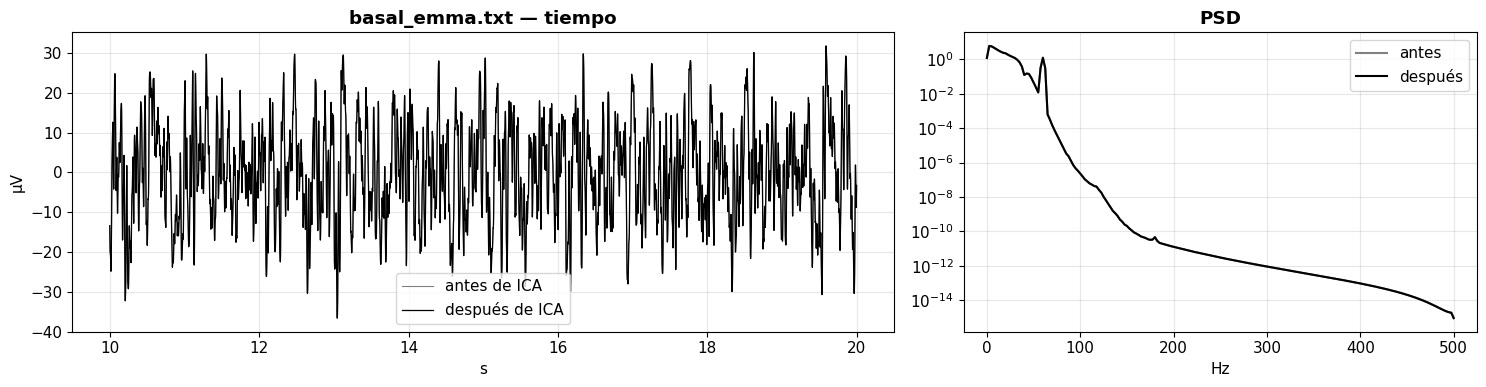

Varianza eliminada por ICA: -0.2 %


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].plot(t[sl], x[sl], color="gray", lw=0.8, label="antes de ICA")
ax[0].plot(t[sl], x_limpia[sl], color="black", lw=0.9, label="después de ICA")
ax[0].set_title(f"{ej} — tiempo"); ax[0].set_xlabel("s"); ax[0].set_ylabel("µV"); ax[0].legend()
for s, nom, col in [(x, "antes", "gray"), (x_limpia, "después", "black")]:
    f, P = psd(s); ax[1].semilogy(f, P, color=col, label=nom)
ax[1].set_title("PSD"); ax[1].set_xlabel("Hz"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Varianza eliminada por ICA: {100 * (1 - np.var(x_limpia) / np.var(x)):.1f} %")

### B.4.6 Aplicamos ICA a todos los registros

In [ ]:
filas = []
for a, r in senales.items():
    r["limpia"], d = ica_un_canal(r["filtrada"])
    malos = d["metricas"].index[d["metricas"]["artefacto"]].tolist()
    filas.append({"archivo": a, "condición": condicion_desde_nombre(a), "ICs tratadas": malos,
                  "acción": [d["metricas"].loc[k, "acción"] for k in malos],
                  "curtosis de las tratadas": [round(v, 1) for v in d["metricas"].loc[malos, "curtosis"]],
                  "% varianza eliminada": round(max(0.0, 100 * (1 - np.var(r["limpia"]) / np.var(r["filtrada"]))), 1)})
resumen_ica = pd.DataFrame(filas).set_index("archivo").loc[tabla_lectura.archivo]
display(resumen_ica)

,condición,ICs tratadas,acción,curtosis de las tratadas,% varianza eliminada
archivo,,,,,
basal_emma.txt,basal,"[1, 2]","[corregir (transitorios), corregir (transitori...","[21684.3, 29492.1]",0.0
abre_cierra_emma.txt,abre_cierra_emma,"[1, 2]","[corregir (transitorios), corregir (transitori...","[19325.0, 30877.2]",0.0
preguntas_emma.txt,preguntas_emma,"[1, 2]","[corregir (transitorios), corregir (transitori...","[40342.4, 93661.8]",0.0
musica_tranquila_emma.txt,musica_tranquila_emma,"[0, 1, 2, 3, 5]","[corregir (transitorios), corregir (transitori...","[221.2, 23451.8, 40865.5, 48.3, 358.0]",30.2
musica_hard_emma.txt,musica_hard_emma,"[0, 1, 2, 3, 5]","[corregir (transitorios), corregir (transitori...","[243.7, 20434.7, 30967.2, 14.7, 339.3]",26.0


### ✍️ Pregunta B.2
1. En `parpadeo_masticacion`, ¿qué componente se trató como artefacto y por qué criterio? ¿Qué sub-banda domina en ella? ¿Qué tipo de evento muestra la gráfica en esa componente?
2. Mira el espectro antes y después: ¿bajó mucho la potencia en **delta** (parpadeos) y por encima de 20 Hz (masticación)? ¿Por qué un parpadeo **continuo y rítmico** es difícil de separar del EEG con un solo canal?
3. En los registros basales, ¿el ICA modificó mucho o poco la señal? ¿Es lo esperado?

✅ **Respuesta B.2**

1. En `parpadeo_masticacion` solo se trató la **componente 5**, por **curtosis = 7.2 > 6**: contiene transitorios. Su sub-banda dominante es **D3 (6.25–12.5 Hz)** y aporta el 26 % de la varianza. La gráfica muestra una oscilación casi continua con **picos bruscos aislados**, por ejemplo cerca de 14.8 s, que coinciden con los eventos grandes de la señal. La corrección recortó solo esos picos (línea oscura) y conservó el resto. Más que un parpadeo "lento", lo que se corrigió son **saltos bruscos**, compatibles con movimientos o con los bordes de la saturación.
2. **No bajaron de forma apreciable.** El espectro antes y después casi coincide, y la varianza eliminada fue solo del **5.8 %**. Las componentes lentas (D5, A5), donde estarían los parpadeos, y la rápida (D1, 96 % de su potencia por encima de 20 Hz), donde estaría la masticación, tienen **curtosis baja** (2.7, 1.3 y 2.3) y se conservaron. *(Conceptual)* Un parpadeo **continuo y rítmico** no es un evento aislado: su distribución no es "picuda" y se superpone en frecuencia con delta y theta. Con un solo canal no hay información espacial (como el mapa topográfico de MNE) para distinguir "ojo" de "cerebro" cuando ocupan las mismas frecuencias.
3. **Muy poco, como se esperaba:**
   - **Basal1 y basal3:** 0 componentes tratadas, 0.0 % de varianza eliminada.
   - **basal2:** 1 componente con curtosis 34.7; 0.7 % eliminado.

   En un registro limpio, el ICA no debe modificar la señal.

<a id="B5"></a>
## B.5 Normalización y segmentación en épocas

### 📖 Normalización (z-score)
La clase presenta la normalización para **facilitar la comparación** entre registros:

$$
z(t) = \frac{x(t) - \mu}{\sigma}
$$

Tras normalizar, cada registro tiene media 0 y desviación 1.
- **Ventaja:** elimina diferencias de **ganancia o contacto** entre sesiones y dispositivos.
- **Desventaja:** también borra la información de **amplitud absoluta**, que puede ser fisiológica.

Por eso es una **decisión** (`NORMALIZAR`). El escalado de las *características* (StandardScaler) se hace siempre, dentro del clasificador.

### 📖 Épocas
Dividimos cada registro en **épocas de 2 s** sin solapamiento. Cada época será una **fila** de la tabla. Se **rechaza** toda época que contenga alguna muestra saturada.

> ⏱️ Con épocas de 2 s, la resolución en frecuencia es $1/T = 0.5$ Hz: suficiente para separar las bandas.

In [ ]:
NORMALIZAR = False     # True = z-score de cada registro antes de cortar épocas
EPOCA_S = 2

def epocas_de(r, epoca_s=EPOCA_S, normalizar=NORMALIZAR, clave="limpia", rechazar=True):
    x = r[clave]
    if normalizar:
        x = (x - x.mean()) / x.std()
    w = int(epoca_s * FS)
    ep, ini = [], []
    for k in range(len(x) // w):
        if rechazar and r["sat_rec"][k*w:(k+1)*w].any():
            continue
        ep.append(x[k*w:(k+1)*w]); ini.append(k * epoca_s)
    return ep, ini

filas = []
for a, r in senales.items():
    ep, _ = epocas_de(r)
    total = len(r[ "limpia"]) // int(EPOCA_S * FS)
    filas.append({"archivo": a, "condición": condicion_desde_nombre(a), "épocas totales": total,
                  "épocas válidas": len(ep), "rechazadas (saturación)": total - len(ep)})
display(pd.DataFrame(filas).set_index("archivo").loc[tabla_lectura.archivo])

,condición,épocas totales,épocas válidas,rechazadas (saturación)
archivo,,,,
basal_emma.txt,basal,43,0,43
abre_cierra_emma.txt,abre_cierra_emma,29,13,16
preguntas_emma.txt,preguntas_emma,71,2,69
musica_tranquila_emma.txt,musica_tranquila_emma,38,0,38
musica_hard_emma.txt,musica_hard_emma,38,0,38


In [ ]:

filas = []

for nombre, r in senales.items():
    adc = r["adc"]

    filas.append({
        "Archivo": nombre,
        "ADC mínimo": np.min(adc),
        "ADC máximo": np.max(adc),
        "Muestras en 0": np.sum(adc == 0),
        "Muestras >= 1018": np.sum(adc >= 1018),
        "Saturación (%)": round(
            100 * np.mean(r["saturada"]), 2
        )
    })

display(pd.DataFrame(filas))


,Archivo,ADC mínimo,ADC máximo,Muestras en 0,Muestras >= 1018,Saturación (%)
0,basal_emma.txt,0.0,1018.0,15715,15459,34.47
1,abre_cierra_emma.txt,0.0,1018.0,252,169,0.66
2,musica_hard_emma.txt,0.0,1019.0,38727,38483,96.03
3,musica_tranquila_emma.txt,0.0,1019.0,38017,37916,94.44
4,preguntas_emma.txt,0.0,1018.0,5516,5400,7.44


<a id="B6"></a>
## B.6 Extracción de características

Describimos cada época de 2 s (200 muestras) con **22 números**, en cinco familias:

| Familia | Características | Definición fácil |
|---|---|---|
| **1. Potencia por banda** | `abs_*` (log₁₀ µV²) y `rel_*` (%) para delta, theta, alfa, beta, gamma | Qué tan fuerte "suena" cada sección de la orquesta |
| **2. Cocientes** *(ingeniería)* | `theta_beta`, `alfa_beta` | Comparan dos ritmos. El cociente theta/beta se asocia a la atención |
| **3. Espectrales** | `f_pico` (frecuencia dominante), `sef90` (frecuencia bajo la cual está el 90 % de la potencia), `entropia` (espectral) | Dónde está la energía y qué tan "repartida" está. Entropía 1 = potencia repartida en todas las frecuencias |
| **4. Hjorth** | `hj_actividad`, `hj_movilidad`, `hj_complejidad` | Varianza de la señal; frecuencia media aproximada; qué tan "irregular" es la forma de onda |
| **5. Estadísticas** | `desv_est`, `asimetria`, `curtosis`, `pico_a_pico` | Amplitud y forma de la distribución de valores |

**Parámetros de Hjorth** (Hjorth, 1970), con $x'$ la derivada:

$$
\text{Actividad} = \mathrm{var}(x), \qquad
\text{Movilidad} = \sqrt{\frac{\mathrm{var}(x')}{\mathrm{var}(x)}}, \qquad
\text{Complejidad} = \frac{\text{Movilidad}(x')}{\text{Movilidad}(x)}
$$

> 💡 **Ingeniería de características:** los cocientes y los logaritmos no son medidas nuevas, sino **transformaciones** de otras. Las usamos porque hacen más evidente una diferencia o vuelven más "normal" la distribución de los datos.

In [ ]:
def caracteristicas_epoca(e, fs=FS):
    f, P = signal.welch(e - e.mean(), fs=fs, nperseg=len(e))
    sel = (f >= 1) & (f <= 45); total = P[sel].sum(); d = {}
    for b, (lo, hi) in BANDAS.items():
        p = P[(f >= lo) & (f < hi)].sum()
        d[f"abs_{b}"] = np.log10(p + 1e-12); d[f"rel_{b}"] = p / total
    d["theta_beta"] = d["rel_theta"] / d["rel_beta"]
    d["alfa_beta"] = d["rel_alfa"] / d["rel_beta"]
    pn = P[sel] / total
    d["f_pico"] = f[sel][np.argmax(P[sel])]
    d["sef90"] = f[sel][np.searchsorted(np.cumsum(pn), 0.9)]
    d["entropia"] = -(pn * np.log2(pn + 1e-12)).sum() / np.log2(sel.sum())
    dx, ddx = np.diff(e), np.diff(e, 2)
    mov = np.sqrt(np.var(dx) / np.var(e))
    d["hj_actividad"] = np.log10(np.var(e)); d["hj_movilidad"] = mov
    d["hj_complejidad"] = np.sqrt(np.var(ddx) / np.var(dx)) / mov
    d["desv_est"] = np.std(e); d["asimetria"] = skew(e); d["curtosis"] = kurtosis(e); d["pico_a_pico"] = np.ptp(e)
    return d


# Buscar un archivo con épocas válidas
archivo_ejemplo = None

for a in tabla_lectura.archivo:
    ep_validas, _ = epocas_de(senales[a])

    if len(ep_validas) > 0:
        archivo_ejemplo = a
        break

if archivo_ejemplo is not None:
    ep_validas, _ = epocas_de(senales[archivo_ejemplo])

    ej_ep = ep_validas[0]

    display(
        pd.Series(
            caracteristicas_epoca(ej_ep)
        ).round(3).to_frame(
            f"época de ejemplo ({archivo_ejemplo})"
        )
    )
else:
    print("No hay épocas válidas")


,época de ejemplo (abre_cierra_emma.txt)
abs_delta,1.078
rel_delta,0.327
abs_theta,0.529
rel_theta,0.092
abs_alfa,0.876
rel_alfa,0.206
abs_beta,1.059
rel_beta,0.313
abs_gamma,0.353
rel_gamma,0.062


<a id="B7"></a>
## B.7 La tabla de características

Juntamos todas las épocas de todos los registros. Cada **fila** es una época de 2 s; cada **columna**, una característica. Las columnas `clase`, `archivo`, `dispositivo` y `t` identifican la época.

In [ ]:
def construir_tabla(epoca_s=EPOCA_S, normalizar=NORMALIZAR, clave="limpia", archivos=None, rechazar=True):
    filas = []
    for a, r in senales.items():
        if archivos is not None and a not in archivos:
            continue
        ep, ini = epocas_de(r, epoca_s, normalizar, clave, rechazar)
        for e, t0 in zip(ep, ini):
            d = caracteristicas_epoca(e)
            d.update({"clase": condicion_desde_nombre(a), "archivo": a, "dispositivo": r["dispositivo"], "t": t0})
            filas.append(d)
    return pd.DataFrame(filas)

tabla = construir_tabla()
CARACTERISTICAS = [c for c in tabla.columns if c not in ("clase", "archivo", "dispositivo", "t")]
CLASES = [c for c in ORDEN if c in tabla.clase.unique()] + [c for c in tabla.clase.unique() if c not in ORDEN]
print(f"Tabla: {len(tabla)} épocas × {len(CARACTERISTICAS)} características")
display(tabla.groupby("clase").size().reindex(CLASES).rename("épocas").to_frame())
display(tabla.groupby("clase")[CARACTERISTICAS].mean().T.reindex(columns=CLASES).round(3))

Tabla: 15 épocas × 22 características


,épocas
clase,
abre_cierra_emma,13
preguntas_emma,2


clase,abre_cierra_emma,preguntas_emma
abs_delta,1.376,1.618
rel_delta,0.373,0.389
abs_theta,1.129,1.169
rel_theta,0.193,0.137
abs_alfa,0.961,1.105
rel_alfa,0.136,0.130
abs_beta,1.185,1.499
rel_beta,0.241,0.292
abs_gamma,0.533,0.726
rel_gamma,0.056,0.052


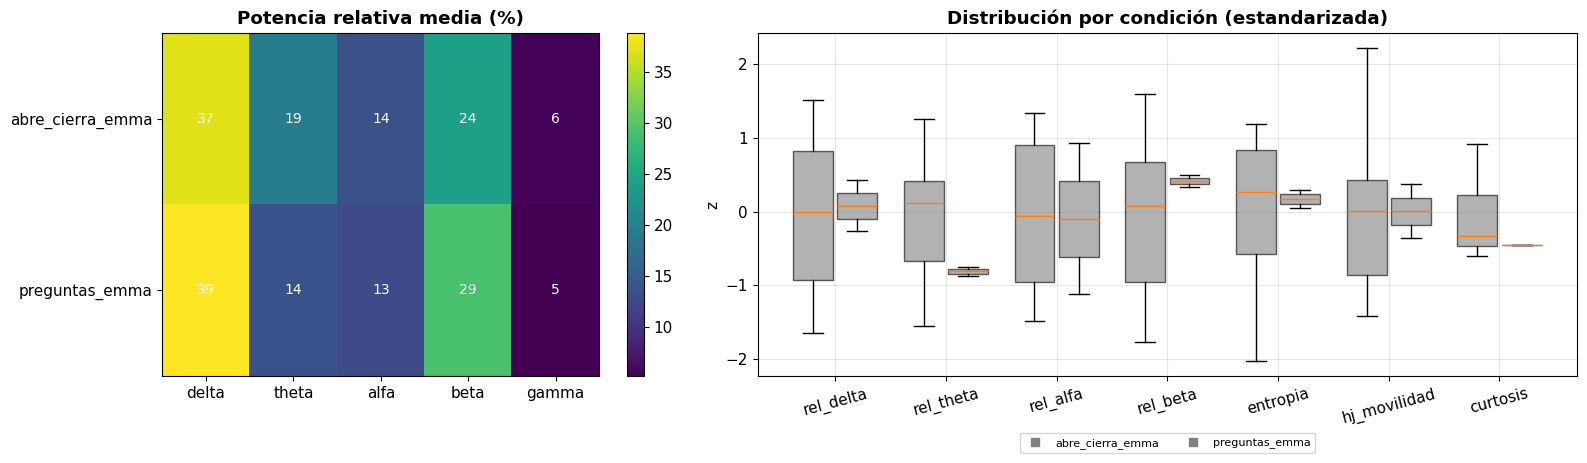

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})
rel = tabla.groupby("clase")[[f"rel_{b}" for b in BANDAS]].mean().reindex(CLASES) * 100
im = ax[0].imshow(rel.values, cmap="viridis", aspect="auto")
ax[0].set_xticks(range(len(BANDAS))); ax[0].set_xticklabels(BANDAS); ax[0].set_yticks(range(len(CLASES))); ax[0].set_yticklabels(CLASES)
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        ax[0].text(j, i, f"{rel.values[i, j]:.0f}", ha="center", va="center", color="w", fontsize=10)
ax[0].set_title("Potencia relativa media (%)"); ax[0].grid(False); plt.colorbar(im, ax=ax[0])

sel = ["rel_delta", "rel_theta", "rel_alfa", "rel_beta", "entropia", "hj_movilidad", "curtosis"]
z = (tabla[sel] - tabla[sel].mean()) / tabla[sel].std()
ancho = 0.8 / len(CLASES)
for j, c in enumerate(CLASES):
    pos = np.arange(len(sel)) + (j - (len(CLASES) - 1) / 2) * ancho
    bp = ax[1].boxplot([z[tabla.clase == c][s] for s in sel], positions=pos, widths=ancho*0.9,
                       patch_artist=True, showfliers=False)
    for caja in bp["boxes"]:
        caja.set_facecolor(COLOR.get(c, "gray")); caja.set_alpha(0.6)
    ax[1].plot([], [], "s", color=COLOR.get(c, "gray"), label=c)
ax[1].set_xticks(np.arange(len(sel))); ax[1].set_xticklabels(sel, rotation=15)
ax[1].set_ylabel("z"); ax[1].set_title("Distribución por condición (estandarizada)")
ax[1].legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout(); plt.show()

### ✍️ Pregunta B.3
1. ¿Qué condición tiene más potencia **delta**? ¿Qué condición tiene la **entropía espectral** más alta?
2. ¿Qué dos o tres características parecen separar mejor las condiciones?

✅ **Respuesta B.3**

1. **Más delta: música estresante** (57 % en promedio por época), seguida de música relajante (39 %). **Entropía espectral más alta: ojos abiertos** (0.891): su potencia está más repartida, con mucha beta y gamma.
2. Las que mejor separan, según el mapa de calor y los boxplots, son:
   - **`rel_delta`:** baja en ojos abiertos (6 %), alta en las músicas;
   - **`rel_beta`:** alta en ojos abiertos (44 %), baja en música estresante (12 %);
   - **`entropia`** y **`hj_movilidad`:** las músicas, sobre todo la estresante, tienen valores mucho menores.

   `curtosis` casi no separa ninguna condición.

<a id="B8"></a>
## B.8 Clasificación y una advertencia importante

Usamos los mismos cinco algoritmos del Laboratorio 11 (Árbol de Decisión, Regresión Logística, Random Forest, KNN y SVM) y la misma regla para **no hacer trampa**: las épocas se agrupan en **bloques de 10 s** y cada bloque va entero a entrenamiento o a prueba (`StratifiedGroupKFold`).

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

MODELOS = {
    "Árbol de Decisión":   lambda: DecisionTreeClassifier(max_depth=5, random_state=0),
    "Regresión Logística": lambda: LogisticRegression(max_iter=3000),
    "Random Forest":       lambda: RandomForestClassifier(n_estimators=200, random_state=0),
    "KNN (k=5)":           lambda: KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)":           lambda: SVC(kernel="rbf"),
}
nuevo_modelo = lambda nombre: make_pipeline(StandardScaler(), MODELOS[nombre]())

def esquema_validacion(tabla, objetivo="clase"):
    grupos = (tabla["archivo"] + "_b" + (tabla["t"] // 10).astype(int).astype(str)).to_numpy()
    n = int(min(5, tabla.assign(g=grupos).groupby(objetivo)["g"].nunique().min()))
    assert n >= 2, "Se necesitan al menos 2 bloques de 10 s por clase."
    return StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=0), grupos, n

def comparar_modelos(tabla, columnas, objetivo="clase"):
    cv, grupos, _ = esquema_validacion(tabla, objetivo)
    filas = []
    for nombre in MODELOS:
        s = cross_validate(nuevo_modelo(nombre), tabla[columnas].to_numpy(), tabla[objetivo].to_numpy(),
                           cv=cv, groups=grupos, scoring=["accuracy", "f1_macro"])
        filas.append({"Modelo": nombre, "Exactitud": s["test_accuracy"].mean(),
                      "F1 macro": s["test_f1_macro"].mean(), "± F1": s["test_f1_macro"].std()})
    return pd.DataFrame(filas).set_index("Modelo")

# Verificar si hay suficientes datos para clasificar
grupos_por_clase = tabla.assign(
    grupo=tabla["archivo"] + "_b" +
    (tabla["t"] // 10).astype(int).astype(str)
).groupby("clase")["grupo"].nunique()

display(grupos_por_clase)

if len(grupos_por_clase) >= 2 and grupos_por_clase.min() >= 2:
    _, grupos, n_pl = esquema_validacion(tabla)

    print(f"{len(tabla)} épocas | {n_pl} pliegues")

    resultados = comparar_modelos(
        tabla, CARACTERISTICAS
    )

    display(resultados.round(3))
else:
    resultados = None
    print("No hay suficientes bloques independientes")
    print("No se puede realizar una clasificación válida")


,grupo
clase,
abre_cierra_emma,5
preguntas_emma,1


No hay suficientes bloques independientes
No se puede realizar una clasificación válida


In [ ]:
mejor = resultados["F1 macro"].idxmax()
cv, grupos, _ = esquema_validacion(tabla)
y = tabla["clase"].to_numpy()
y_pred = cross_val_predict(nuevo_modelo(mejor), tabla[CARACTERISTICAS].to_numpy(), y, cv=cv, groups=grupos)
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1]})
ConfusionMatrixDisplay.from_predictions(y, y_pred, labels=CLASES, cmap="Blues", ax=ax[0], colorbar=False,
                                        xticks_rotation=25)
ax[0].set_title(f"Matriz de confusión — {mejor}"); ax[0].grid(False)
rf = nuevo_modelo("Random Forest").fit(tabla[CARACTERISTICAS].to_numpy(), y)
imp = pd.Series(rf[-1].feature_importances_, index=CARACTERISTICAS).sort_values()
imp.tail(10).plot.barh(ax=ax[1], color="tab:green"); ax[1].set_title("Random Forest: 10 características más importantes")
plt.tight_layout(); plt.show()

TypeError: 'NoneType' object is not subscriptable

🔎 **Verificación adicional (solo en el solucionario):** predicciones del mejor modelo desglosadas por archivo y dispositivo.

In [ ]:
# 🔎 Verificación adicional (solucionario): ¿qué archivos producen los errores de la matriz de confusión?
display(pd.crosstab(tabla["archivo"] + " [" + tabla["dispositivo"] + "]", pd.Series(y_pred, name="predicción"))
        .reindex(columns=CLASES, fill_value=0))

NameError: name 'y_pred' is not defined

### ⚠️ La advertencia: ¿estamos clasificando condiciones o dispositivos?
En la Parte A vimos que se usaron **dos BITalino distintos** y que uno de ellos tenía mucha más interferencia. Si las condiciones están repartidas de forma desigual entre dispositivos, el clasificador podría estar aprendiendo **qué equipo se usó** y no **qué estaba haciendo el cerebro**. A esto se le llama **variable de confusión** (*confound*).

**Prueba:** usamos las mismas características para predecir el **dispositivo**. Si lo predice casi perfecto, las características llevan una "huella" del equipo.

In [ ]:
reparto = pd.crosstab(tabla["clase"], tabla["dispositivo"]).reindex(CLASES)
display(reparto.rename_axis(index="condición", columns="dispositivo"))
if tabla["dispositivo"].nunique() > 1:
    res_disp = comparar_modelos(tabla, CARACTERISTICAS, objetivo="dispositivo")
    print("¿Se puede predecir el DISPOSITIVO a partir de las características?")
    display(res_disp[["F1 macro", "± F1"]].round(3))
else:
    print("Solo hay un dispositivo: no aplica.")

dispositivo,2A:08,78:F6
condición,,
basal,14,47
ojos_abiertos,0,29
parpadeo_masticacion,21,0
musica_relajante,25,0
musica_estresante,23,0


¿Se puede predecir el DISPOSITIVO a partir de las características?


,F1 macro,± F1
Modelo,,
Árbol de Decisión,0.953,0.041
Regresión Logística,1.000,0.000
Random Forest,0.995,0.011
KNN (k=5),1.000,0.000
SVM (RBF),0.995,0.011


### ✍️ Pregunta B.4
1. ¿Qué modelo obtuvo el mejor F1? ¿Qué condiciones se confunden más en la matriz de confusión?
2. ¿Qué características usó más el Random Forest? ¿Tienen sentido fisiológico o podrían reflejar diferencias técnicas?
3. ¿Qué tan bien se predice el **dispositivo**? Mirando la tabla de reparto, ¿qué condiciones están "atadas" a un solo dispositivo? ¿Qué implica esto para interpretar el resultado de la clasificación?

✅ **Respuesta B.4**

1. **Random Forest, F1 = 0.714 ± 0.082** (azar = 0.20), seguido de Regresión Logística (0.702) y SVM (0.701). Las confusiones principales son:
   - **basal ↔ música relajante:** 11 épocas basales predichas como relajante y 5 de relajante predichas como basal;
   - **basal ↔ ojos abiertos:** 7 y 6;
   - **relajante ↔ estresante:** 5 y 7.

   **Parpadeo** se reconoce casi perfecto (20 de 21).
2. Las más importantes son **`desv_est`, `hj_actividad`, `abs_beta`, `abs_gamma`** y `pico_a_pico`. Casi todas miden **amplitud absoluta**. Tienen una parte fisiológica, por ejemplo los artefactos grandes del parpadeo, pero también **reflejan diferencias técnicas**: ganancia, contacto de los electrodos y nivel de ruido de cada equipo.
3. El **dispositivo** se predice con **F1 = 0.99–1.00**, casi perfecto. **ojos_abiertos** solo existe en el equipo 78:F6, y **parpadeo, relajante y estresante** solo en el 2A:08. La verificación 🔎 lo confirma: de las 14 épocas de **basal3**, grabada con el equipo de las músicas, **ninguna** se clasifica como basal; **11 se predicen como música relajante** y 3 como estresante. En cambio, Basal1 (mismo equipo que las otras basales) acierta 33 de 33.

   **Conclusión:** buena parte de lo que el modelo "aprende" es **qué equipo se usó**. El F1 de 0.714 **no puede interpretarse** como capacidad de reconocer estados cerebrales.

<a id="B9"></a>
## B.9 Conclusiones de la Parte B

| Etapa | Idea clave |
|---|---|
| Filtrado | Pasa-banda 1–45 Hz y notch en el **alias** (40 Hz), no en 60 Hz, porque Fs = 100 Hz |
| Ritmos | La potencia relativa por banda resume el estado. Con electrodos frontales la alfa se ve poco |
| ICA | Separa fuentes independientes. Con un canal se usa **Wavelet-ICA**: corrige los transitorios bruscos y elimina la interferencia de red, pero no separa artefactos continuos (parpadeo rítmico, masticación) que se superponen a las bandas del EEG |
| Normalización y épocas | El z-score facilita comparar, pero borra la amplitud. Se rechazan épocas saturadas |
| Características | 22 por época: bandas, cocientes, espectrales, Hjorth y estadísticas |
| Clasificación | Resultados altos **no garantizan** que se reconozca la fisiología. Hay que descartar variables de confusión como el dispositivo |

[⬆️ Volver al índice](#indice)

---
<a id="cuestionario"></a>
# 📝 Cuestionario final: experimenta con tus datos

La función `experimento(...)` repite la Parte B con los parámetros que elijas:

```python
experimento(condiciones=None,    # None = todas, o una lista: ["musica_relajante", "musica_estresante"]
            usar_ica=True,       # aplicar o no la limpieza con Wavelet-ICA
            notch=NOTCH_HZ,      # 40, 60 o None
            quitar_lineas=True,  # notch angosto en las líneas de interferencia detectadas en A.4
            normalizar=False,    # z-score de cada registro
            epoca_s=2,           # duración de las épocas en segundos
            rechazar_saturadas=True,  # descartar las épocas con saturación
            objetivo="clase")    # "clase" (condición) o "dispositivo"
```

Devuelve `(resultados, tabla, resumen)`.

In [ ]:
def experimento(condiciones=None, usar_ica=True, notch=NOTCH_HZ, quitar_lineas=QUITAR_LINEAS, normalizar=False,
                epoca_s=2, objetivo="clase", rechazar_saturadas=True, columnas=None, mostrar=True):
    archivos = [a for a in senales if condiciones is None or condicion_desde_nombre(a) in condiciones]
    if len({condicion_desde_nombre(a) for a in archivos}) < 2:
        print(f"⚠️ No hay al menos 2 condiciones disponibles entre {condiciones}.")
        return None, None, None
    resumen = []
    for a in archivos:
        r = senales[a]
        r["exp"] = filtrar_eeg(r["eeg_uV"][i0:], notch=notch, lineas=lineas_de(a, quitar_lineas))
        n_red = n_trans = 0
        if usar_ica:
            r["exp"], d = ica_un_canal(r["exp"])
            n_red = int((d["metricas"]["acción"] == "eliminar (red)").sum())
            n_trans = int((d["metricas"]["acción"] == "corregir (transitorios)").sum())
        f, P = psd(r["exp"])
        resumen.append({"archivo": a, "ICs de red eliminadas": n_red, "ICs con transitorios corregidas": n_trans,
                        "pico 40 Hz tras procesar": round(pico_relativo(f, P), 1)})
    tab = construir_tabla(epoca_s, normalizar, "exp", archivos, rechazar_saturadas)
    cols = CARACTERISTICAS if columnas is None else columnas
    try:
        res = comparar_modelos(tab, cols, objetivo)
    except (AssertionError, ValueError) as e:
        res = None
        print(f"⚠️ No se pudo clasificar: {e}")
    resumen = pd.DataFrame(resumen).merge(tab.groupby("archivo").size().rename("épocas").reset_index(), on="archivo")
    if mostrar:
        print(f"▶ condiciones={condiciones or 'todas'} | ICA={usar_ica} | notch={notch} | líneas={quitar_lineas} | normalizar={normalizar} | "
              f"época={epoca_s} s | objetivo={objetivo}")
        display(resumen)
        if res is not None:
            display(res[["F1 macro", "± F1"]].T.round(3))
    return res, tab, resumen

print("✅ Función experimento() lista.")

✅ Función experimento() lista.


### Pregunta 1 — ¿Se distingue la música relajante de la estresante?
Ejecuta `experimento(["musica_relajante", "musica_estresante"])`. Ambas se grabaron con el **mismo dispositivo**, así que aquí no hay confusión por equipo. ¿Qué F1 obtienes? Usando la tabla devuelta, ¿qué banda cambia más entre ambas?

### Pregunta 2 — ¿Ayuda el ICA?
Compara `experimento(usar_ica=True)` con `experimento(usar_ica=False)`. ¿Cambia el F1? En la tabla devuelta, compara el promedio de `curtosis` y `pico_a_pico` de `parpadeo_masticacion` con y sin ICA. Repite la comparación con `rechazar_saturadas=False`. ¿Cuándo se nota más el efecto del ICA? ¿Por qué?

### Pregunta 3 — ¿Qué pasa si no quitamos las interferencias?
a) Para aislar el efecto del notch, desactiva el filtrado de líneas angostas (`quitar_lineas=False`). Compara `experimento(notch=40, quitar_lineas=False)`, `experimento(notch=60, quitar_lineas=False)` y `experimento(notch=None, quitar_lineas=False)`. Mira *pico 40 Hz tras procesar*, *ICs de red eliminadas*, el promedio de `rel_gamma` por condición y el F1. ¿Sirve el notch de 60 Hz? Sin notch, ¿el ICA detecta la interferencia por sí solo? ¿Por qué podría **subir** el F1 si dejamos la interferencia?
b) Ejecuta `experimento(quitar_lineas=False)`. ¿Cómo cambian `rel_theta` y `f_pico` en los registros basales del dispositivo con líneas angostas?

### Pregunta 4 — Normalizar, ¿ayuda o perjudica?
Ejecuta `experimento(normalizar=True)` y `experimento(normalizar=True, objetivo="dispositivo")`. Compáralos con `normalizar=False`. ¿Qué pasa con la capacidad de reconocer la condición y el dispositivo? ¿Qué características dejan de ser útiles al normalizar?

### Pregunta 5 — Duración de la época
Prueba `epoca_s=1`, `2` y `4`. ¿Cómo cambia el número de épocas, la resolución en frecuencia ($1/T$) y el F1? ¿Qué duración elegirías?

In [ ]:
# Pregunta 1 — Música relajante vs estresante (mismo dispositivo)
res_m, tab_m, resu_m = experimento(["musica_relajante", "musica_estresante"])
bandas_rel = [f"rel_{b}" for b in BANDAS]
medias = tab_m.groupby("clase")[bandas_rel + ["entropia", "f_pico", "theta_beta", "alfa_beta"]].mean()
medias[bandas_rel] *= 100
display(medias.T.rename(index={f"rel_{b}": f"rel_{b} (%)" for b in BANDAS}).round(3))

▶ condiciones=['musica_relajante', 'musica_estresante'] | ICA=True | notch=40 | líneas=True | normalizar=False | época=2 s | objetivo=clase


,archivo,ICs de red eliminadas,ICs con transitorios corregidas,pico 40 Hz tras procesar,épocas
0,musica_estresante.txt,0,0,0.0,23
1,musica_relajante.txt,0,1,0.7,25


Modelo,Árbol de Decisión,Regresión Logística,Random Forest,KNN (k=5),SVM (RBF)
F1 macro,0.567,0.485,0.455,0.497,0.483
± F1,0.231,0.203,0.087,0.177,0.177


clase,musica_estresante,musica_relajante
rel_delta (%),56.739,38.955
rel_theta (%),16.587,22.179
rel_alfa (%),11.375,14.432
rel_beta (%),12.247,19.219
rel_gamma (%),3.027,5.170
entropia,0.665,0.751
f_pico,1.717,2.660
theta_beta,1.630,1.403
alfa_beta,0.928,0.815


✅ **Respuesta 1 — Música relajante vs. estresante**

Ambas se grabaron con el mismo equipo (2A:08), con 2 minutos de diferencia. El F1 va de **0.618** (Árbol de Decisión) a **0.784** (KNN), con mucha variación entre pliegues (± 0.05 a 0.19). Hay cierta separación, pero inestable.

La banda que más cambia es **delta**: **56.7 %** en la estresante frente a **39.0 %** en la relajante. La relajante tiene más theta (22.2 % vs. 16.6 %), alfa (14.4 % vs. 11.4 %) y beta (19.2 % vs. 12.2 %), y por eso mayor entropía (0.751 vs. 0.665).

*(Conceptual)* Más delta en un electrodo frontal con ojos cerrados puede deberse a **movimientos oculares lentos o tensión** y no necesariamente a un cambio cerebral. Además, es una sola grabación por música, así que no se puede generalizar.

In [ ]:
# Pregunta 2 — Con y sin ICA, rechazando o no las épocas saturadas
filas_f1, comp = {}, {}
cols = ["rel_delta", "rel_gamma", "curtosis", "pico_a_pico"]
for rech in [True, False]:
    for ica_on in [True, False]:
        res_x, tab_x, _ = experimento(usar_ica=ica_on, rechazar_saturadas=rech, mostrar=False)
        nombre = f"{'con' if ica_on else 'sin'} ICA | {'rechazando' if rech else 'SIN rechazar'} saturadas"
        filas_f1[nombre] = res_x["F1 macro"]
        comp[nombre] = tab_x[tab_x.clase == "parpadeo_masticacion"][cols].mean()
        comp[nombre]["épocas de parpadeo"] = (tab_x.clase == "parpadeo_masticacion").sum()
display(pd.DataFrame(filas_f1).round(3))
display(pd.DataFrame(comp).round(3))

,con ICA | rechazando saturadas,sin ICA | rechazando saturadas,con ICA | SIN rechazar saturadas,sin ICA | SIN rechazar saturadas
Modelo,,,,
Árbol de Decisión,0.563,0.595,0.601,0.600
Regresión Logística,0.633,0.641,0.659,0.659
Random Forest,0.647,0.650,0.692,0.684
KNN (k=5),0.600,0.593,0.627,0.613
SVM (RBF),0.679,0.679,0.695,0.675


,con ICA | rechazando saturadas,sin ICA | rechazando saturadas,con ICA | SIN rechazar saturadas,sin ICA | SIN rechazar saturadas
rel_delta,0.301,0.301,0.417,0.405
rel_gamma,0.132,0.132,0.101,0.099
curtosis,0.277,0.271,0.321,0.345
pico_a_pico,48.497,48.391,57.502,58.593
épocas de parpadeo,21.000,21.000,40.000,40.000


✅ **Respuesta 2 — ¿Ayuda el ICA?**

| Configuración | Mejor F1 | Épocas de parpadeo | Curtosis media | Pico a pico medio (µV) |
|---|---|---|---|---|
| Con ICA, rechazando saturadas | 0.714 | 21 | 0.277 | 48.5 |
| Sin ICA, rechazando saturadas | 0.729 | 21 | 0.271 | 48.4 |
| Con ICA, **sin** rechazar saturadas | 0.746 | 40 | 0.321 | 57.5 |
| Sin ICA, **sin** rechazar saturadas | 0.740 | 40 | 0.345 | 58.6 |

- **Rechazando épocas saturadas, el ICA casi no cambia nada.** Los transitorios que corrige coinciden con las épocas saturadas, que de todas formas se descartan.
- **Sin rechazar épocas, el efecto se nota algo más:** baja la curtosis (0.345 → 0.321) y el pico a pico (58.6 → 57.5 µV).
- En ningún caso el F1 cambia más que la variación entre pliegues.

**Conclusión:** con un canal, el ICA corrige **transitorios bruscos**, pero el rechazo de épocas saturadas ya resuelve casi lo mismo.

In [ ]:
# Pregunta 3a — ¿Notch en 40 Hz, en 60 Hz o ninguno? (sin el filtrado de líneas angostas, para aislar el efecto)
filas, gam, f1 = [], {}, {}
for nombre, kw in [("notch 40 Hz", dict(notch=40)), ("notch 60 Hz", dict(notch=60)), ("sin notch", dict(notch=None))]:
    res_n, tab_n, resu_n = experimento(quitar_lineas=False, mostrar=False, **kw)
    gam[nombre] = tab_n.groupby("clase")["rel_gamma"].mean() * 100
    f1[nombre] = res_n["F1 macro"]
    for _, f_ in resu_n.iterrows():
        filas.append({"configuración": nombre, "archivo": f_["archivo"],
                      "ICs de red eliminadas": f_["ICs de red eliminadas"],
                      "pico 40 Hz tras procesar": f_["pico 40 Hz tras procesar"]})
display(pd.DataFrame(filas).pivot(index="archivo", columns="configuración").loc[tabla_lectura.archivo])
display(pd.DataFrame(gam).reindex(CLASES).round(1).rename_axis("rel_gamma (%)"))
display(pd.DataFrame(f1).round(3).rename_axis("F1 macro"))

⚠️ Notch de 60 Hz imposible: está por encima de Nyquist (50 Hz). No se aplicó.
⚠️ Notch de 60 Hz imposible: está por encima de Nyquist (50 Hz). No se aplicó.
⚠️ Notch de 60 Hz imposible: está por encima de Nyquist (50 Hz). No se aplicó.
⚠️ Notch de 60 Hz imposible: está por encima de Nyquist (50 Hz). No se aplicó.
⚠️ Notch de 60 Hz imposible: está por encima de Nyquist (50 Hz). No se aplicó.
⚠️ Notch de 60 Hz imposible: está por encima de Nyquist (50 Hz). No se aplicó.
⚠️ Notch de 60 Hz imposible: está por encima de Nyquist (50 Hz). No se aplicó.


ICs de red eliminadas                        \
configuración                      notch 40 Hz notch 60 Hz sin notch   
archivo                                                                
Basal1.txt                                   0           0         0   
ojos_abiertos.txt                            0           0         0   
basal2.txt                                   0           0         0   
parpadeo_masticacion.txt                     0           1         1   
basal3.txt                                   0           1         1   
musica_relajante.txt                         0           1         1   
musica_estresante.txt                        0           1         1   

                         pico 40 Hz tras procesar                        
configuración                         notch 40 Hz notch 60 Hz sin notch  
archivo                                                                  
Basal1.txt                                    0.0         1.9       1.9  
ojos_abiertos.txt                             0.0         0.7       0.7  
basal2.txt                                    0.0         1.7       1.7  
parpadeo_masticacion.txt                      0.0        19.7      19.7  
basal3.txt                                    0.0        31.8      31.8  
musica_relajante.txt                          0.7       148.7     148.7  
musica_estresante.txt                         0.0        76.0      76.0

,notch 40 Hz,notch 60 Hz,sin notch
rel_gamma (%),,,
basal,10.6,12.9,12.9
ojos_abiertos,17.9,22.6,22.6
parpadeo_masticacion,13.2,0.3,0.3
musica_relajante,5.2,4.8,4.8
musica_estresante,3.0,1.7,1.7


,notch 40 Hz,notch 60 Hz,sin notch
F1 macro,,,
Árbol de Decisión,0.621,0.802,0.802
Regresión Logística,0.632,0.773,0.773
Random Forest,0.635,0.810,0.810
KNN (k=5),0.621,0.776,0.776
SVM (RBF),0.643,0.834,0.834


✅ **Respuesta 3a — ¿Notch en 40 Hz, en 60 Hz o ninguno?** (sin quitar las líneas angostas)

- **El notch de 60 Hz no sirve:** el cuaderno avisa que es imposible (60 Hz > Nyquist) y no lo aplica. Por eso sus resultados son **idénticos** a no usar notch.
- **Sin notch, el ICA detecta la interferencia por sí solo:** elimina **una componente de red** en cada uno de los 4 registros del dispositivo 2A:08, y en ninguno del 78:F6. Pero **no la quita del todo**: el pico de 40 Hz queda en 19.7 (parpadeo), 31.8 (basal3), 148.7 (relajante) y 76.0 (estresante) veces sobre sus vecinos. Con el notch en 40 Hz queda en 0.0–0.7.
- **`rel_gamma`** de parpadeo cae de 13.2 % a 0.3 %, porque la componente de red eliminada se lleva casi toda su gamma. En ojos abiertos sube de 17.9 % a 22.6 %.
- **El F1 sube sin notch**, de 0.611–0.714 a 0.803–0.877. **No es una mejora real**: la interferencia de 40 Hz existe solo en un equipo, así que funciona como "etiqueta" del dispositivo y facilita separar las condiciones grabadas con cada uno. Es un ejemplo claro de cómo un artefacto puede **inflar** el rendimiento.

In [ ]:
# Pregunta 3b — Sin quitar las líneas angostas
res_l, tab_l, _ = experimento(quitar_lineas=False, mostrar=False)
comp = pd.DataFrame({
    "rel_theta (%) con líneas quitadas": tabla.groupby("archivo")["rel_theta"].mean() * 100,
    "rel_theta (%) SIN quitar líneas": tab_l.groupby("archivo")["rel_theta"].mean() * 100,
    "f_pico con líneas quitadas": tabla.groupby("archivo")["f_pico"].median(),
    "f_pico SIN quitar líneas": tab_l.groupby("archivo")["f_pico"].median()}).loc[tabla_lectura.archivo]
display(comp.round(1))
print(f"Mejor F1 sin quitar líneas: {res_l['F1 macro'].max():.3f}  (con líneas quitadas: {resultados['F1 macro'].max():.3f})")

,rel_theta (%) con líneas quitadas,rel_theta (%) SIN quitar líneas,f_pico con líneas quitadas,f_pico SIN quitar líneas
archivo,,,,
Basal1.txt,13.3,33.4,2.0,4.5
ojos_abiertos.txt,11.4,20.1,13.5,4.5
basal2.txt,10.9,23.4,14.2,4.5
parpadeo_masticacion.txt,15.2,15.2,2.5,2.5
basal3.txt,26.0,26.0,3.2,3.2
musica_relajante.txt,22.2,22.2,2.0,2.0
musica_estresante.txt,16.6,16.6,1.5,1.5


Mejor F1 sin quitar líneas: 0.643  (con líneas quitadas: 0.679)


✅ **Respuesta 3b — Sin quitar las líneas angostas**

| Registro (78:F6) | rel_theta con líneas quitadas | rel_theta SIN quitarlas | f_pico con / sin |
|---|---|---|---|
| Basal1 | 13.3 % | **33.4 %** | 2.0 / **4.5** Hz |
| basal2 | 10.9 % | **23.4 %** | 14.2 / **4.5** Hz |
| ojos_abiertos | 11.4 % | **20.1 %** | 13.5 / **4.5** Hz |

Sin quitar las líneas, **la theta de los basales se duplica o triplica** y la frecuencia pico de los tres registros pasa a ser **4.5 Hz**: la línea de interferencia. Alguien podría concluir erróneamente que hay "un ritmo theta de 4.5 Hz". En el dispositivo 2A:08 no hay cambios, porque no tiene esas líneas. El F1 queda igual (0.714), pero **las características dejan de ser fisiológicamente interpretables**.

In [ ]:
# Pregunta 4 — Normalizar la señal (z-score por registro)
r_c0, t_c0, _ = experimento(normalizar=False, mostrar=False)
r_c1, t_c1, _ = experimento(normalizar=True, mostrar=False)
r_d0, _, _ = experimento(normalizar=False, objetivo="dispositivo", mostrar=False)
r_d1, _, _ = experimento(normalizar=True, objetivo="dispositivo", mostrar=False)
display(pd.DataFrame({"condición — sin normalizar": r_c0["F1 macro"], "condición — normalizada": r_c1["F1 macro"],
                      "dispositivo — sin normalizar": r_d0["F1 macro"], "dispositivo — normalizada": r_d1["F1 macro"]}).round(3))
amp = ["desv_est", "hj_actividad", "pico_a_pico", "abs_alfa"]
display(pd.concat({"sin normalizar": t_c0.groupby("clase")[amp].mean(),
                   "normalizada": t_c1.groupby("clase")[amp].mean()}, axis=1).reindex(CLASES).round(2))

,condición — sin normalizar,condición — normalizada,dispositivo — sin normalizar,dispositivo — normalizada
Modelo,,,,
Árbol de Decisión,0.563,0.505,0.953,0.886
Regresión Logística,0.633,0.551,1.000,0.906
Random Forest,0.647,0.616,0.995,0.920
KNN (k=5),0.600,0.528,1.000,0.925
SVM (RBF),0.679,0.606,0.995,0.941


sin normalizar                                    \
                           desv_est hj_actividad pico_a_pico abs_alfa   
clase                                                                   
basal                          1.86         0.33       10.59    -0.28   
ojos_abiertos                  2.10         0.64       11.69    -0.02   
parpadeo_masticacion           8.65         1.85       48.50     0.99   
musica_relajante               4.61         1.31       24.85     0.65   
musica_estresante              6.17         1.55       32.61     0.71   

                     normalizada                                    
                        desv_est hj_actividad pico_a_pico abs_alfa  
clase                                                               
basal                       0.99        -0.02        5.64    -0.63  
ojos_abiertos               0.99        -0.02        5.50    -0.67  
parpadeo_masticacion        0.79        -0.23        4.44    -1.09  
musica_relajante            0.88        -0.13        4.75    -0.79  
musica_estresante           0.84        -0.18        4.42    -1.03

✅ **Respuesta 4 — ¿Normalizar ayuda o perjudica?**

| Objetivo | Sin normalizar (mejor F1) | Normalizada (mejor F1) |
|---|---|---|
| Condición | 0.714 | 0.677 |
| Dispositivo | 1.000 | 0.932 |

- **Perjudica la clasificación de condiciones:** el F1 baja en los 5 modelos (por ejemplo, KNN de 0.673 a 0.557).
- **Reduce la confusión por dispositivo, pero no la elimina:** el dispositivo se sigue prediciendo con 0.87–0.93.

**Características que dejan de ser útiles:** las de **amplitud absoluta**. Con la señal normalizada:
- `desv_est` queda cerca de 1 en todas las condiciones (0.79–0.99);
- `hj_actividad` cerca de 0;
- `pico_a_pico` muy parecido (4.4–5.6).

Antes iban de 1.86 a 8.65 µV y de 10.6 a 48.5 µV. El z-score borra justo la información que el Random Forest más usaba (B.8), y con ella parte de la huella del equipo y parte de la diferencia real (por ejemplo, la gran amplitud del parpadeo). El resto de la huella del dispositivo está en la **forma del espectro**, que el z-score no cambia.

In [ ]:
# Pregunta 5 — Duración de la época
filas = []
for T in [1, 2, 4]:
    res_e, tab_e, _ = experimento(epoca_s=T, mostrar=False)
    filas.append({"época (s)": T, "resolución 1/T (Hz)": 1 / T, "épocas válidas": len(tab_e),
                  "mejor modelo": res_e["F1 macro"].idxmax(), "mejor F1": round(res_e["F1 macro"].max(), 3),
                  "F1 promedio 5 modelos": round(res_e["F1 macro"].mean(), 3)})
display(pd.DataFrame(filas))

,época (s),resolución 1/T (Hz),épocas válidas,mejor modelo,mejor F1,F1 promedio 5 modelos
0,1,1.00,338,Random Forest,0.683,0.642
1,2,0.50,159,SVM (RBF),0.679,0.624
2,4,0.25,72,Árbol de Decisión,0.688,0.604


✅ **Respuesta 5 — Duración de la época**

| Época | Resolución 1/T | Épocas válidas | Mejor F1 | F1 promedio de los 5 modelos |
|---|---|---|---|---|
| 1 s | 1.00 Hz | 338 | 0.727 (SVM) | 0.702 |
| 2 s | 0.50 Hz | 159 | 0.714 (RF) | 0.686 |
| 4 s | 0.25 Hz | 72 | 0.742 (Árbol) | 0.631 |

- **Más larga** → mejor resolución en frecuencia y estimaciones espectrales más estables, pero **muchas menos épocas**: de 338 a 72.
- El **mejor F1 apenas cambia** (0.714–0.742). El **promedio de los 5 modelos baja claramente** con 4 s (0.631), porque hay pocos datos para entrenar.

**Elección: 2 s**, como término medio. Con 1 s la resolución de 1 Hz es demasiado gruesa para separar bien bandas estrechas como theta (4 Hz de ancho). Con 4 s quedan muy pocas épocas por registro: basal2 y basal3 solo duran ~30 s.

---
## ✅ Conclusión general del laboratorio (grupo de referencia)

1. **Revisar los datos fue decisivo.** Se descubrió el aliasing de la red (60 → 40 Hz), líneas de interferencia en 4.6, 9.15 y 25 Hz que fingían ser "theta", saturación y el uso de **dos dispositivos**.
2. **Ritmos:** con el montaje frontal Fp1–Fp2 no se observa alfa dominante ni bloqueo alfa al abrir los ojos. Sí aumenta la beta con ojos abiertos (de 26.9 % a 43.1 % respecto de Basal1).
3. **ICA:** separa fuentes cuando hay varios canales (demostración simulada). Con un canal, el Wavelet-ICA corrige transitorios bruscos y detecta la interferencia de red, pero **no separa artefactos continuos** que se superponen al EEG (parpadeo rítmico, masticación). El ejemplo de MNE muestra por qué: los criterios más potentes son **espaciales** (topografía).
4. **Características:** 22 por época (potencia por banda, cocientes, entropía, Hjorth y estadísticas). La ingeniería (logaritmos y cocientes) mejora su interpretabilidad.
5. **Clasificación:** F1 = 0.714 para 5 condiciones, pero el dispositivo se predice con F1 ≈ 1.00 y dejar la interferencia **sube** el F1 a ~0.88. **Un buen número no garantiza que el modelo reconozca fisiología.**
6. **Recomendación para próximas adquisiciones:** usar **un solo equipo** en todas las condiciones, muestrear a **≥ 250 Hz** si se quiere estudiar gamma y evitar el aliasing, y repetir cada condición varias veces.

---
<a id="entregables"></a>
# 📦 Entregables y referencias

### Entregables
1. Este cuaderno ejecutado **con tus registros**, con todas las preguntas ✍️ respondidas.
2. El cuestionario final con tus experimentos.
3. El archivo `caracteristicas_eeg.csv` (se genera en la celda siguiente).

### Referencias
1. L. De La Cruz, *Tratamiento de señal EEG* (diapositivas del curso), UPCH.
2. MNE-Python, *Removing muscle ICA components*. https://mne.tools/stable/auto_examples/preprocessing/muscle_ica.html
3. D. Dharmaprani et al., "A comparison of independent component analysis algorithms and measures to discriminate between EEG and artifact components", *IEEE EMBC*, 2016, pp. 825–828. doi: 10.1109/EMBC.2016.7590828
4. A. Hyvärinen y E. Oja, "Independent component analysis: algorithms and applications", *Neural Networks*, vol. 13, pp. 411–430, 2000.
5. N. P. Castellanos y V. A. Makarov, "Recovering EEG brain signals: Artifact suppression with wavelet enhanced independent component analysis", *J. Neurosci. Methods*, vol. 158, pp. 300–312, 2006.
6. B. Hjorth, "EEG analysis based on time domain properties", *Electroencephalogr. Clin. Neurophysiol.*, vol. 29, pp. 306–310, 1970.
7. P. D. Welch, "The use of fast Fourier transform for the estimation of power spectra", *IEEE Trans. Audio Electroacoust.*, vol. 15, pp. 70–73, 1967.
8. J. A. Urigüen y B. Garcia-Zapirain, "EEG artifact removal—state-of-the-art and guidelines", *J. Neural Eng.*, vol. 12, 031001, 2015.
9. PLUX Wireless Biosignals, *BITalino (r)evolution — EEG Sensor Datasheet* (fórmula de conversión).

[⬆️ Volver al índice](#indice)

In [ ]:
tabla.to_csv("caracteristicas_eeg.csv", index=False)
print("✅ Archivo generado: caracteristicas_eeg.csv", tabla.shape)
try:
    from google.colab import files
    files.download("caracteristicas_eeg.csv")
except ImportError:
    pass

✅ Archivo generado: caracteristicas_eeg.csv (159, 26)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>